# NFL Win Predictor & Dynamic Game Flow Visual Analytics

**Author:** Henri Murthy  
**Course:** ITCS 4123 / Visual Analytics  
**Role:** Solo contributor  
**Dataset:** nflscrapR / Kaggle play-by-play, regular seasons 2009–2018 (449,371 plays in the project archive).

## Project question and deliverables

How does in-game state relate to home-team win probability, which plays create the largest probability changes, and how do fourth-down conversion outcomes vary with distance and field position? This notebook provides seven original visualizations, a leakage-aware held-out win model, an interactive game-flow hub, and a dimension-reduction and subspace-analysis suite. The analysis is descriptive: model probabilities are not causal estimates, betting advice, or guarantees of future performance.

## Platform, LLM integration, and prompt strategy

Python is the analysis platform. Pandas and NumPy prepare play-by-play data; Matplotlib produces reproducible static figures and custom marks; scikit-learn trains and evaluates the win model and dimension-reduction methods; Plotly creates the browser-native interactive views. The original dashboard uses Plotly and ipywidgets for game/team selectors, event filters, and linked detail. The added DR and DPMatrix/Tree figures use Plotly controls and are emitted as HTML, so those controls do not require a live Python kernel.

LLM support was used as a learning and coding aid. For the initial dashboard, the iterative strategy was to translate the project mockup and analyst tasks into a coordinated layout, ask for Plotly/ipywidgets patterns to link timeline, quarter, field position, and event details, refine rendering issues such as annotations and responsive legends, then check the result against actual data. Representative prompt paraphrases: *How can the game-flow timeline link to field and event details in a responsive Plotly/ipywidgets hub?*; *How should quarter markers sit behind probability traces while the event timeline remains readable?*; and *How can the field map and fourth-down summaries show sample counts and uncertainty without implying a causal recommendation?*

For this extension, the strategy was to specify the held-out sampling and feature matrix first, request a linear/nonlinear comparison and explicit neighborhood-preservation checks, then design browser-native controls that update shared Plotly traces without Python callbacks. The final iteration checks deterministic sampling, tooltip provenance, fallback behavior, and whether tree/matrix metrics describe the same held-out snapshots as the projections. These are illustrative paraphrases, not a verbatim prompt log. Suggested code was reviewed and adapted; data preparation, model scores, metrics, and visual outputs are computed by this notebook.

## Methodology and reproducibility

The loader tries KaggleHub (`maxhorowitz/nflplaybyplay2009to2016`), a local CSV named for 2009–2018, and then `archive (1).zip`. The source must cover 2009–2018 and contain the required play-by-play fields. Do not put Kaggle credentials in this notebook. `snapshot_rows` retains at most one observation per game per five-minute time bin to limit repeated-play dominance. Seasons 2009–2016 are training/validation data (2015–2016 selects model settings); seasons 2017–2018 are the untouched chronological test period. Tied games are omitted from the binary win/loss target. `home_wp_post` is a comparison reference only, never a predictor feature.

The 17 model/DR dimensions are nine base features (`home_score_diff`, `game_seconds_remaining`, `qtr`, `down`, `ydstogo`, `yardline_100`, `home_offense`, `home_timeouts_remaining`, `away_timeouts_remaining`) and eight engineered features (`abs_score_diff`, `score_sum`, `timeout_diff`, `score_per_minute`, `down_distance`, `late_close`, `red_zone`, `territory`). Model settings are selected on validation log loss, then the model is refit on 2009–2016. Lower log loss is better. The added DR sample is a deterministic outcome-stratified sample of up to 2,500 held-out snapshots, with all selected case-game snapshots included. Median imputation and `StandardScaler` are fit to this visualization sample only; the fixed seed is 42. Held-out labels are used for coloring and quality diagnostics, not to train the win predictor.

### Environment setup

Use Python 3.10 or later. Run `py -m venv .venv`, then in PowerShell `.venv\Scripts\Activate.ps1` (macOS/Linux: `source .venv/bin/activate`). Install with `python -m pip install --upgrade pip` and `python -m pip install -r requirements.txt`, select `.venv` as the notebook kernel, and run all cells. Requirements include `nbformat`, `nbconvert`, and `umap-learn`; if UMAP is unavailable, the DR cell uses scikit-learn t-SNE as a nonlinear fallback. If KaggleHub cannot retrieve the archive, place the 2009–2018 CSV beside the notebook. Dataset: [Kaggle play-by-play](https://www.kaggle.com/datasets/maxhorowitz/nflplaybyplay2009to2016).

## Case study 1 — Following a high-volatility game

A broadcast analyst needs to explain when control changed, what happened, and how the win forecast responded. The notebook selects the held-out game with the largest cumulative absolute play-to-play change in the source probability (or uses `CASE_GAME_ID` when set), then moves from game-flow context to high-swing plays and drive-level changes. The default saved analysis describes Baltimore at Cleveland on October 7, 2018: tied 9–9 at regulation's end, Cleveland won 12–9 in overtime. Source `home_wp_post` drops from about 0.922 to 0.025 around a missed 55-yard field-goal attempt despite the tie score; similar abrupt values on overtime timeout rows are a data/model consistency warning, not a real 90-point change in Cleveland's chance. Cross-check probability traces against score, clock, and the independently trained model. These views support an auditable narrative but do not establish that a specific play caused the result. The selection rule and plots update when another game is chosen.

## Case study 2 — Evaluating fourth-down choices

An analyst wants to compare observed conversion rates by yards-to-go and field position, while checking attempt counts and uncertainty. On the supplied archive there were 4,776 fourth-down attempts with explicit outcomes and an overall 49.0% conversion rate; one-yard attempts converted 64.7% of the time (1,787 attempts), compared with 20.5% for 11-or-more yards (493 attempts). The notebook reports counts and Wilson intervals and marks sparse field-position cells. These are selected attempts, not the counterfactual value of going for it rather than punting or kicking; they do not justify a causal coaching recommendation.

## Case study 3 — High-dimensional game state and subspace exploration

PCA and UMAP/t-SNE compare a global linear summary with a locally focused manifold view of the same standardized 17D held-out game states. Colors expose game clock, score differential, tactical regimes, prediction confidence, and outcome residuals. The PCA loading heatmap connects each axis to original features; trustworthiness, k-neighbor overlap, and sampled pair-distance correlation quantify how much local structure survives projection. The interactive explorer coordinates PCA, nonlinear projection, and a raw yardline-versus-clock view; hover retains original feature values. The dimension-projection tree reports class-separability (silhouette) and mean absolute held-out prediction residual for root, domain subspaces, and pairwise leaves. The matrix compares pairwise tactical projections and lets a reader focus on all snapshots or spatial, situational, and late/close contexts.

PCA finds orthogonal axes that maximize global variance and support linear reconstruction; it may compress or overlap localized regimes. UMAP builds a fuzzy neighborhood graph and optimizes a low-dimensional layout to retain local affinities. If UMAP is unavailable, t-SNE is the nonlinear comparison; it likewise emphasizes local neighborhoods. Nonlinear methods can separate late-and-close or red-zone states that PCA overlaps, but apparent distances between UMAP/t-SNE clusters and their sizes are not reliable measures of original 17D distances or population density. Interpret local neighbors and tactical context, not global cluster spacing.

## Original visualization suite and references

Figures 1–5 are the five core visualizations; figures 6–7 are custom-coded field-position and drive-impact views submitted for bonus consideration. The seven detailed charts are complemented by the interactive dashboard, an interface rather than an additional visualization counted toward the five. The dashboard aligns win probability and recent momentum with quarter shading, an event timeline and filters, field-position context, fourth-down detail, and a linked-play selector that highlights the timeline and field location. Its legend and controls wrap for narrow layouts; team badges are abbreviations, not official logo artwork. The selected model's validation comparison and held-out log-loss results are printed by the executable analysis; the saved run reported 0.4842/0.4834 validation loss for original/engineered features and 0.4348/0.4339/0.4359 held-out loss for baseline/selected/source-reference probabilities. Treat those saved-run values as historical; rerunning recomputes them from the loaded archive.

- Yurko, R., Ventura, S., & Horowitz, M. (2019). *nflscrapR: An R Package for Accessing Open Source Football Data and Modeling Outcomes with Expected Points and Win Probability.* Annals of Applied Statistics; arXiv:1802.00998.
- Perin, C., Vuillemot, R., & Fekete, J.-D. (2013). *SoccerStories: A Kick-off for Visual Soccer Analysis.* IEEE Transactions on Visualization and Computer Graphics, 19(12), 2506–2515.
- Ren, D. & Yuan, X. (2013). *Dimension Projection Matrix/Tree: Interactive Subspace Visual Exploration and Analysis of High Dimensional Data.* IEEE InfoVis.
- Dataset: [Detailed NFL Play-by-Play Data 2009–2018](https://www.kaggle.com/datasets/maxhorowitz/nflplaybyplay2009to2016), identified in the proposal as nflscrapR.

## Peer evaluation

**Team Member:** Henri Murthy — **100% contribution** (Sole contributor responsible for data engineering, predictive modeling, dimensionality reduction analysis, DPMatrix/Tree bonus implementation, interactive Plotly visualizations, and report documentation).

## Exporting the interactive report

After running the notebook top-to-bottom:

```powershell
jupyter nbconvert --to html --execute HenriMurthyVisProject.ipynb --output HenriMurthyVisProject.html
```

The new DR and DPMatrix/Tree charts are emitted as Plotly HTML, with the Plotly JavaScript bundle embedded once, so their controls work without a running Python kernel. The legacy ipywidgets hub remains useful in a live notebook; its Python callbacks are not part of standalone HTML interaction.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle, FancyArrowPatch
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss
from sklearn.calibration import calibration_curve

plt.rcParams.update({
    'figure.figsize': (11, 5.5),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.22,
    'font.size': 10,
})
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

# ---- Data access: KaggleHub, local CSV, then supplied archive ----
PROJECT_DIR = Path.cwd()
def has_local_dataset(folder):
    return (
        (folder / 'archive (1).zip').is_file()
        or any(
            '2009' in path.name and '2018' in path.name
            for path in folder.glob('*.csv')
        )
    )

if not has_local_dataset(PROJECT_DIR) and has_local_dataset(PROJECT_DIR.parent):
    PROJECT_DIR = PROJECT_DIR.parent
ZIP_PATH = PROJECT_DIR / 'archive (1).zip'
PREFER_KAGGLE = True
KAGGLE_HANDLE = 'maxhorowitz/nflplaybyplay2009to2016'
CSV_PATH = None
DATA_SOURCE = None
REQUIRED_COLUMNS = {
    'game_id', 'game_date', 'home_team', 'away_team', 'posteam_type',
    'qtr', 'quarter_seconds_remaining', 'game_seconds_remaining',
    'down', 'ydstogo', 'yardline_100',
    'play_type', 'yards_gained', 'home_wp_post', 'epa', 'desc', 'drive',
    'total_home_score', 'total_away_score', 'home_timeouts_remaining',
    'away_timeouts_remaining', 'fourth_down_converted',
    'fourth_down_failed', 'touchdown', 'interception', 'fumble_lost',
}

if PREFER_KAGGLE:
    try:
        import kagglehub

        downloaded = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        kaggle_csvs = [
            p for p in downloaded.rglob('*.csv')
            if '2009' in p.name and '2018' in p.name
        ]
        if not kaggle_csvs:
            raise FileNotFoundError(
                f'Kaggle download at {downloaded} did not contain a 2009–2018 CSV.'
            )
        CSV_PATH = kaggle_csvs[0]
        DATA_SOURCE = f'KaggleHub: {KAGGLE_HANDLE} ({CSV_PATH.name})'
    except Exception as exc:
        warnings.warn(
            f'Kaggle access failed ({type(exc).__name__}: {exc}). '
            'Trying a local 2009–2018 CSV, then the supplied archive.',
            RuntimeWarning,
        )

if CSV_PATH is None:
    local_csvs = sorted(
        path for path in PROJECT_DIR.glob('*.csv')
        if '2009' in path.name and '2018' in path.name
    )
    if local_csvs:
        CSV_PATH = local_csvs[0]
        DATA_SOURCE = f'Local CSV: {CSV_PATH.name}'

if CSV_PATH is not None:
    df = pd.read_csv(
        CSV_PATH,
        usecols=lambda name: name in REQUIRED_COLUMNS,
        na_values=['NA'],
        low_memory=False,
    )
elif ZIP_PATH.is_file():
    with ZipFile(ZIP_PATH) as archive:
        members = [
            name for name in archive.namelist()
            if name.lower().endswith('.csv')
            and '2009' in Path(name).name
            and '2018' in Path(name).name
        ]
        if not members:
            raise FileNotFoundError(
                'The supplied ZIP has no CSV whose filename covers 2009–2018.'
            )
        member = members[-1]
        with archive.open(member) as source:
            df = pd.read_csv(
                source,
                usecols=lambda name: name in REQUIRED_COLUMNS,
                na_values=['NA'],
                low_memory=False,
            )
        DATA_SOURCE = f'{ZIP_PATH.name} -> {member}'
else:
    raise FileNotFoundError(
        'No usable dataset was found. Allow KaggleHub access, or place a '
        '2009–2018 CSV or archive (1).zip beside the notebook. Dataset: '
        'https://www.kaggle.com/datasets/maxhorowitz/nflplaybyplay2009to2016'
    )

missing = REQUIRED_COLUMNS.difference(df.columns)
if missing:
    raise ValueError(f'Dataset is missing required columns: {sorted(missing)}')
df['game_date'] = pd.to_datetime(df['game_date'], errors='coerce')
df['game_year'] = df['game_date'].dt.year
df['game_id'] = df['game_id'].astype(str)
print(f'Data source: {DATA_SOURCE}')
print(f'Rows: {len(df):,} | seasons: {df.game_year.min()}–{df.game_year.max()}')
print(f'Games: {df.game_id.nunique():,} | columns loaded: {len(df.columns)}')

# ---- Game outcomes, time snapshots, and leakage-safe predictor ----
for column in [
    'qtr', 'quarter_seconds_remaining', 'game_seconds_remaining',
    'down', 'ydstogo', 'yardline_100',
    'yards_gained', 'home_wp_post', 'epa', 'total_home_score',
    'total_away_score', 'home_timeouts_remaining', 'away_timeouts_remaining',
    'fourth_down_converted', 'fourth_down_failed', 'drive',
    'touchdown', 'interception', 'fumble_lost',
]:
    df[column] = pd.to_numeric(df[column], errors='coerce')

score_rows = df.dropna(
    subset=[
        'qtr', 'game_seconds_remaining',
        'total_home_score', 'total_away_score',
    ]
)
ordered = score_rows.sort_values(
    ['game_id', 'qtr', 'game_seconds_remaining'],
    ascending=[True, True, False],
)
final_rows = ordered.groupby('game_id', sort=False).tail(1).copy()
outcomes = final_rows[['game_id', 'total_home_score', 'total_away_score']].copy()
outcomes['home_win'] = np.where(
    outcomes['total_home_score'] > outcomes['total_away_score'],
    1.0,
    np.where(
        outcomes['total_home_score'] < outcomes['total_away_score'],
        0.0,
        np.nan,
    ),
)
df = df.merge(outcomes[['game_id', 'home_win']], on='game_id', how='left')

snapshot_rows = df.dropna(
    subset=[
        'game_year', 'game_seconds_remaining', 'qtr',
        'total_home_score', 'total_away_score', 'home_win',
    ]
).copy()
snapshot_rows['time_bin'] = (
    snapshot_rows['game_seconds_remaining'].clip(lower=0) // 300
).astype(int)
snapshot_rows = (
    snapshot_rows.sort_values(
        ['game_id', 'game_seconds_remaining'],
        ascending=[True, True],
    )
    .drop_duplicates(['game_id', 'time_bin'], keep='first')
    .copy()
)
snapshot_rows['home_score_diff'] = (
    snapshot_rows['total_home_score'] - snapshot_rows['total_away_score']
)
snapshot_rows['home_offense'] = np.where(
    snapshot_rows['posteam_type'].eq('home'),
    1.0,
    np.where(snapshot_rows['posteam_type'].eq('away'), 0.0, np.nan),
)
BASE_FEATURES = [
    'home_score_diff', 'game_seconds_remaining', 'qtr', 'down', 'ydstogo',
    'yardline_100', 'home_offense', 'home_timeouts_remaining',
    'away_timeouts_remaining',
]
for feature in BASE_FEATURES:
    snapshot_rows[feature] = pd.to_numeric(
        snapshot_rows[feature], errors='coerce'
    )
snapshot_rows['abs_score_diff'] = snapshot_rows['home_score_diff'].abs()
snapshot_rows['score_sum'] = (
    snapshot_rows['total_home_score'] + snapshot_rows['total_away_score']
)
snapshot_rows['timeout_diff'] = (
    snapshot_rows['home_timeouts_remaining']
    - snapshot_rows['away_timeouts_remaining']
)
snapshot_rows['score_per_minute'] = snapshot_rows['home_score_diff'] / (
    1 + snapshot_rows['game_seconds_remaining'] / 60
)
snapshot_rows['down_distance'] = snapshot_rows['down'] * snapshot_rows['ydstogo']
snapshot_rows['late_close'] = (
    (snapshot_rows['game_seconds_remaining'] <= 600)
    & (snapshot_rows['home_score_diff'].abs() <= 8)
).astype(float)
snapshot_rows['red_zone'] = (
    snapshot_rows['yardline_100'] <= 20
).astype(float)
snapshot_rows['territory'] = pd.cut(
    snapshot_rows['yardline_100'],
    bins=[-1, 20, 50, 80, 100],
    labels=False,
).astype(float)
ENGINEERED_FEATURES = [
    'abs_score_diff', 'score_sum', 'timeout_diff', 'score_per_minute',
    'down_distance', 'late_close', 'red_zone', 'territory',
]
FEATURES = [*BASE_FEATURES, *ENGINEERED_FEATURES]

train = snapshot_rows[snapshot_rows['game_year'].between(2009, 2016)].copy()
test = snapshot_rows[snapshot_rows['game_year'].between(2017, 2018)].copy()
if train.empty or test.empty:
    raise ValueError(
        f'Chronological split is empty: train={len(train)}, test={len(test)}. '
        'Confirm the source contains seasons 2009–2018.'
    )
if train['home_win'].nunique() < 2:
    raise ValueError('Training data must include both home wins and home losses.')

selection_train = train[train['game_year'].between(2009, 2014)]
selection_validation = train[train['game_year'].between(2015, 2016)]
if selection_train.empty or selection_validation.empty:
    raise ValueError('Model selection requires seasons 2009–2016.')

baseline_parameters = {
    'loss': 'log_loss', 'learning_rate': 0.08, 'max_iter': 140,
    'max_leaf_nodes': 15, 'min_samples_leaf': 35,
    'l2_regularization': 2.0, 'random_state': 42,
}
engineered_parameters = {
    'loss': 'log_loss', 'learning_rate': 0.06, 'max_iter': 220,
    'max_leaf_nodes': 15, 'min_samples_leaf': 60,
    'l2_regularization': 3.0, 'random_state': 42,
}
baseline_candidate = HistGradientBoostingClassifier(**baseline_parameters)
engineered_candidate = HistGradientBoostingClassifier(**engineered_parameters)
baseline_candidate.fit(
    selection_train[BASE_FEATURES], selection_train['home_win']
)
engineered_candidate.fit(
    selection_train[FEATURES], selection_train['home_win']
)
baseline_validation_loss = log_loss(
    selection_validation['home_win'],
    baseline_candidate.predict_proba(selection_validation[BASE_FEATURES])[:, 1],
    labels=[0, 1],
)
engineered_validation_loss = log_loss(
    selection_validation['home_win'],
    engineered_candidate.predict_proba(selection_validation[FEATURES])[:, 1],
    labels=[0, 1],
)
use_engineered_features = (
    engineered_validation_loss < baseline_validation_loss
)
model_features = FEATURES if use_engineered_features else BASE_FEATURES
model_parameters = (
    engineered_parameters if use_engineered_features else baseline_parameters
)
print(f'2015–2016 model-selection log loss, original features: {baseline_validation_loss:.4f}')
print(f'2015–2016 model-selection log loss, engineered features: {engineered_validation_loss:.4f}')
print(f'Model selected using validation seasons: {"engineered" if use_engineered_features else "original"} features')

baseline_model = HistGradientBoostingClassifier(**baseline_parameters)
baseline_model.fit(train[BASE_FEATURES], train['home_win'])
test['baseline_probability'] = baseline_model.predict_proba(
    test[BASE_FEATURES]
)[:, 1].clip(1e-6, 1 - 1e-6)

win_model = HistGradientBoostingClassifier(**model_parameters)
win_model.fit(train[model_features], train['home_win'])
test['predicted_home_win'] = win_model.predict_proba(
    test[model_features]
)[:, 1]
test['model_probability'] = test['predicted_home_win'].clip(1e-6, 1 - 1e-6)
test['reference_probability'] = test['home_wp_post'].clip(1e-6, 1 - 1e-6)
test_eval = test.dropna(
    subset=['home_win', 'model_probability', 'reference_probability']
).copy()
if test_eval.empty:
    raise ValueError('No complete held-out rows are available for log-loss evaluation.')

model_logloss = log_loss(
    test_eval['home_win'],
    test_eval['model_probability'],
    labels=[0, 1],
)
baseline_logloss = log_loss(
    test_eval['home_win'],
    test_eval['baseline_probability'],
    labels=[0, 1],
)
reference_logloss = log_loss(
    test_eval['home_win'],
    test_eval['reference_probability'],
    labels=[0, 1],
)
print(
    f'Train: {train.game_year.min()}–{train.game_year.max()} '
    f'({train.game_id.nunique():,} games, {len(train):,} snapshots)'
)
print(
    f'Test: {test_eval.game_year.min()}–{test_eval.game_year.max()} '
    f'({test_eval.game_id.nunique():,} games, {len(test_eval):,} snapshots)'
)
tie_count = int(
    outcomes['total_home_score'].eq(outcomes['total_away_score']).sum()
)
missing_outcome_games = df['game_id'].nunique() - outcomes['game_id'].nunique()
print(f'Tied games excluded from binary win/loss modeling: {tie_count}')
print(f'Games without a complete final score excluded: {missing_outcome_games}')
print(f'Original-feature baseline log loss: {baseline_logloss:.4f}')
print(f'Engineered-feature model log loss: {model_logloss:.4f}')
print(f'Source home_wp_post reference log loss: {reference_logloss:.4f}')

# Select the most volatile test game by the sum of observed play-to-play
# home-probability changes; this is a reproducible descriptive selection rule.
CASE_GAME_ID = None  # Optional: set to a game_id string from the held-out seasons.
test_game_ids = set(test_eval['game_id'])
holdout_plays = df[df['game_id'].isin(test_game_ids)].copy()
holdout_plays = holdout_plays.sort_values(
    ['game_id', 'qtr', 'game_seconds_remaining'],
    ascending=[True, True, False],
)
holdout_plays['observed_home_swing'] = (
    holdout_plays.groupby('game_id')['home_wp_post'].diff().abs()
)
volatility = holdout_plays.groupby('game_id')['observed_home_swing'].sum()
if CASE_GAME_ID is None:
    CASE_GAME_ID = str(volatility.idxmax())
else:
    CASE_GAME_ID = str(CASE_GAME_ID)
if CASE_GAME_ID not in test_game_ids:
    raise ValueError(
        f'CASE_GAME_ID {CASE_GAME_ID} is not in the 2017–2018 held-out seasons.'
    )

case_snapshot = test_eval[test_eval['game_id'].eq(CASE_GAME_ID)].copy()
case_plays = df[df['game_id'].eq(CASE_GAME_ID)].copy()
case_plays = case_plays.sort_values(
    ['qtr', 'game_seconds_remaining'],
    ascending=[True, False],
)
home_team = case_plays['home_team'].dropna().iloc[0]
away_team = case_plays['away_team'].dropna().iloc[0]
final_score = outcomes[outcomes['game_id'].eq(CASE_GAME_ID)].iloc[0]
home_won = bool(final_score['home_win'])
print(
    f'Case-study game: {CASE_GAME_ID} | {away_team} at {home_team} | '
    f'final {int(final_score.total_away_score)}–{int(final_score.total_home_score)} '
    f'(home {"win" if home_won else "loss"})'
)


Data source: KaggleHub: maxhorowitz/nflplaybyplay2009to2016 (NFL Play by Play 2009-2018 (v5).csv)
Rows: 449,371 | seasons: 2009–2018
Games: 2,526 | columns loaded: 27
2015–2016 model-selection log loss, original features: 0.4842
2015–2016 model-selection log loss, engineered features: 0.4834
Model selected using validation seasons: engineered features
Train: 2009–2016 (2,019 games, 26,244 snapshots)
Test: 2017–2018 (493 games, 4,539 snapshots)
Tied games excluded from binary win/loss modeling: 14
Games without a complete final score excluded: 0
Original-feature baseline log loss: 0.4348
Engineered-feature model log loss: 0.4339
Source home_wp_post reference log loss: 0.4359
Case-study game: 2018100703 | BAL at CLE | final 9–12 (home win)


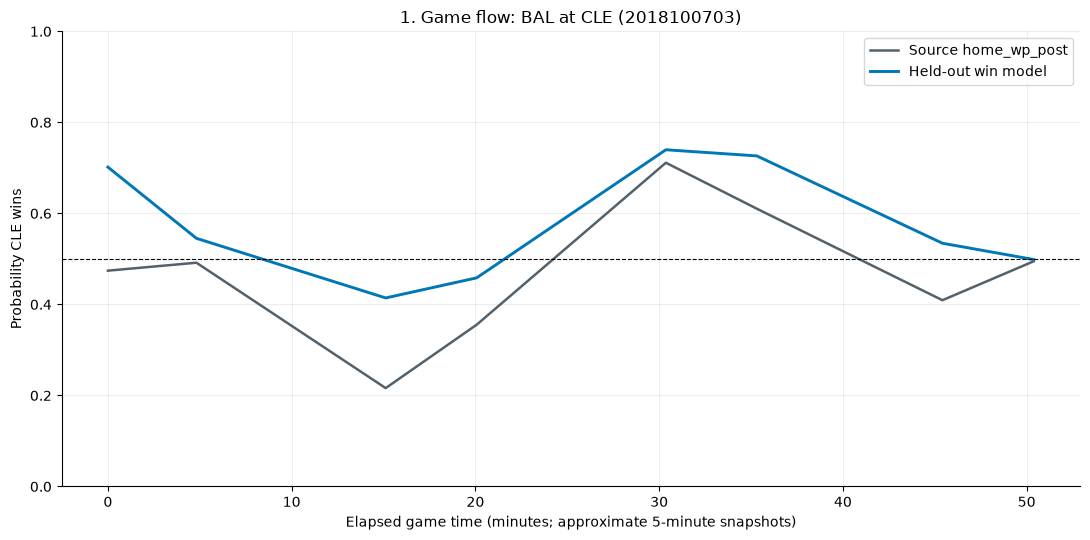

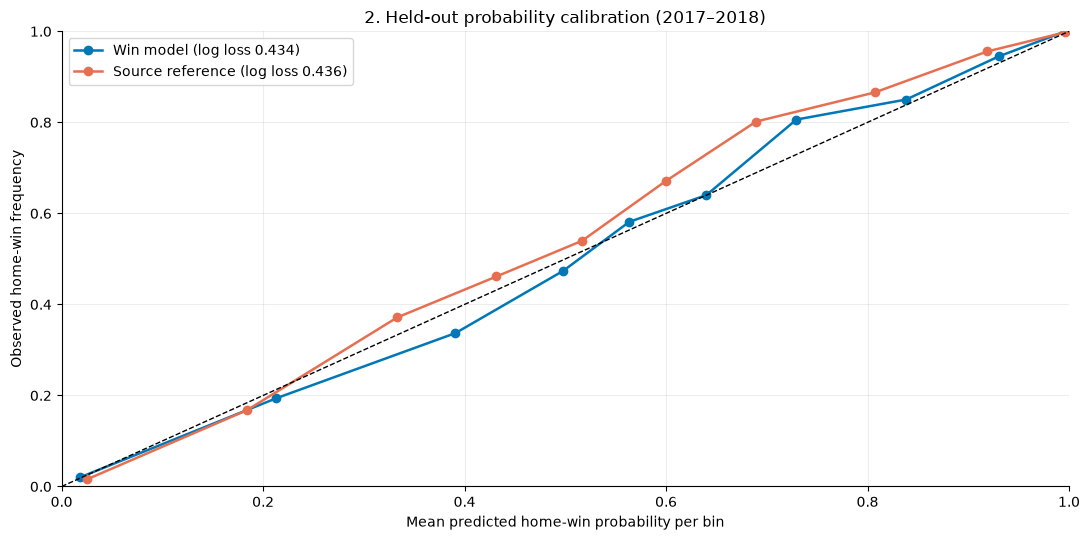

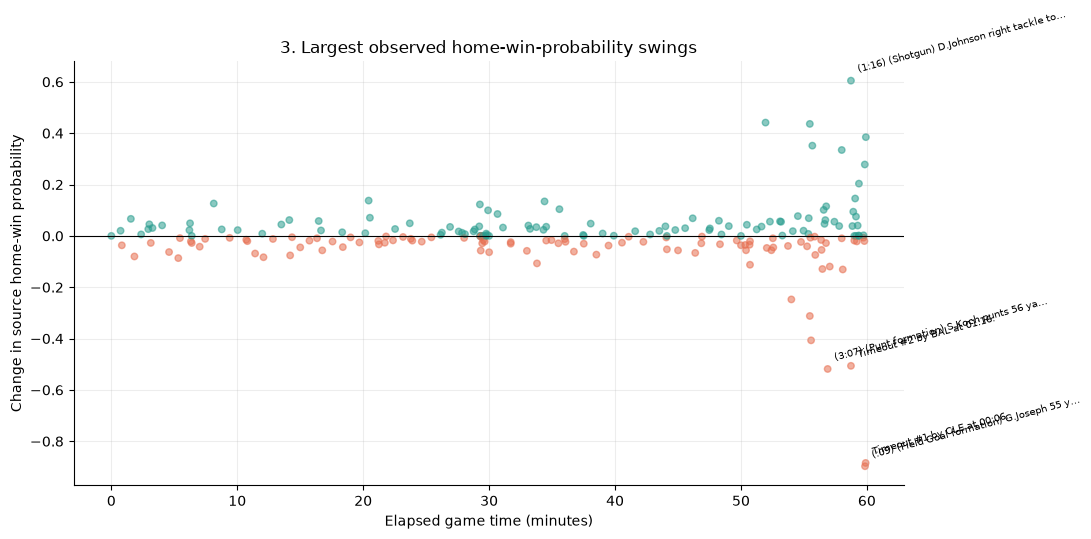

Largest observed swing plays:


,qtr,game_seconds_remaining,play_type,home_wp_change,home_wp_post,desc
420052,5,187.0,punt,-0.518,0.253,(3:07) (Punt formation) S.Koch punts 56 yards ...
420058,5,76.0,run,0.605,0.605,(1:16) (Shotgun) D.Johnson right tackle to BAL...
420057,5,76.0,no_play,-0.506,0.000,Timeout #2 by BAL at 01:16.
420025,4,9.0,field_goal,-0.897,0.025,(:09) (Field Goal formation) G.Joseph 55 yard ...
420061,5,6.0,no_play,-0.884,0.000,Timeout #1 by CLE at 00:06.


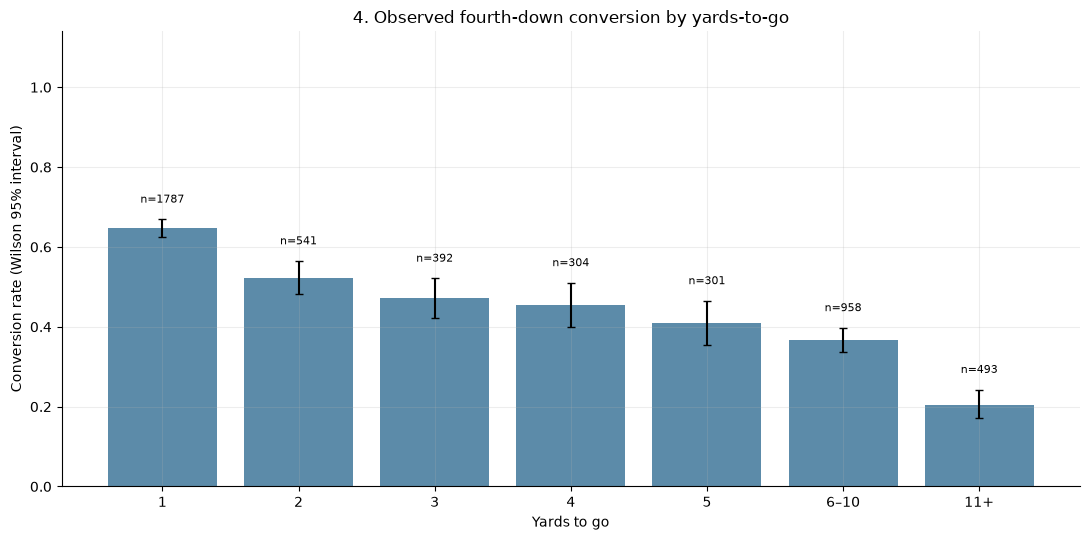

Fourth-down attempts with explicit outcomes: 4,776


,distance_group,successes,attempts,rate,low,high,error_low,error_high
0,1,1157,1787,0.647,0.625,0.669,0.022,0.022
1,2,283,541,0.523,0.481,0.565,0.042,0.042
2,3,185,392,0.472,0.423,0.521,0.049,0.049
3,4,138,304,0.454,0.399,0.510,0.055,0.056
4,5,123,301,0.409,0.355,0.465,0.054,0.056
5,6–10,351,958,0.366,0.336,0.397,0.030,0.031
6,11+,101,493,0.205,0.172,0.243,0.033,0.038


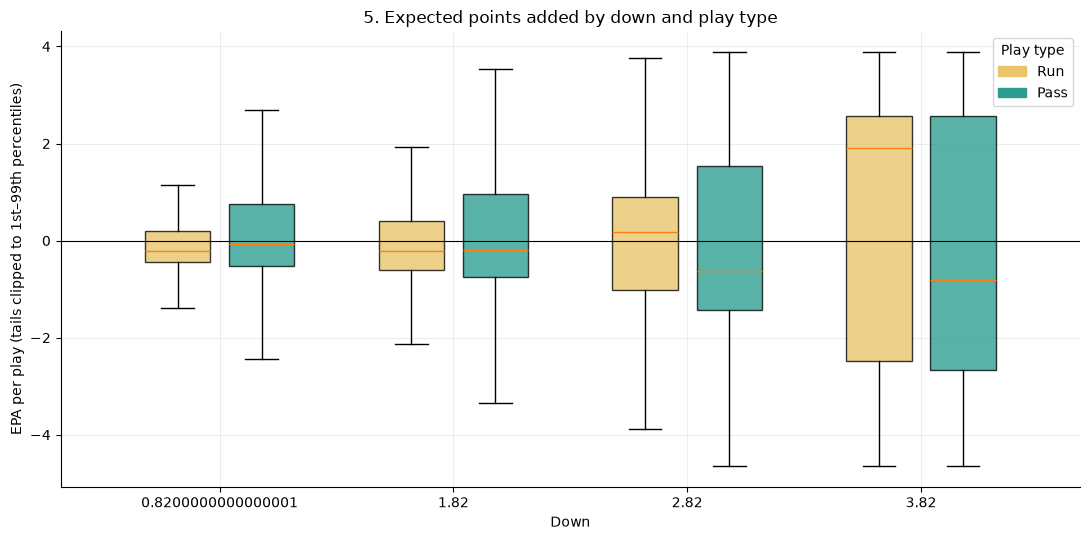

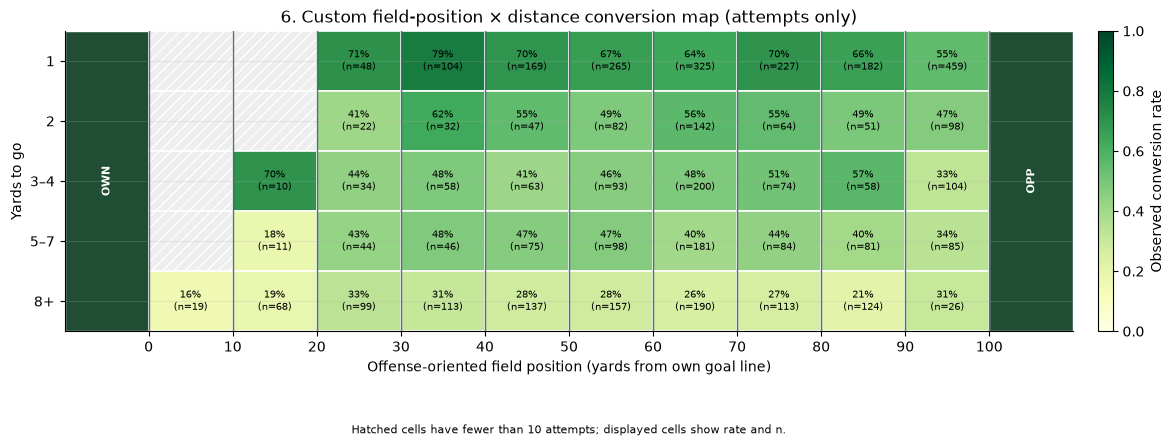

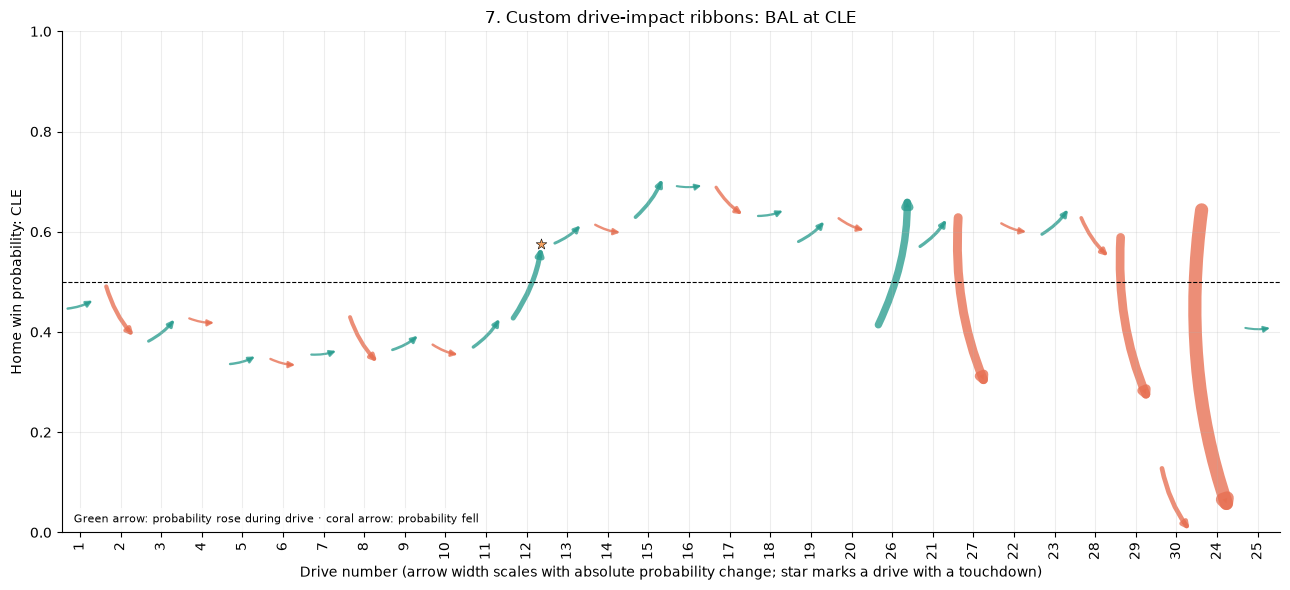

Case Study 2 evidence: 4,776 fourth-down attempts with explicit outcomes; overall observed conversion rate 49.0%.
Interpretation reminder: these are selected attempts, not the causal value of choosing to go for it.


In [2]:
# ---- Figure 1 (core): selected game's game-flow win-probability timeline ----
game_plot = case_snapshot.sort_values(
    'game_seconds_remaining', ascending=False
).copy()
game_plot['elapsed_minutes'] = (
    game_plot['game_seconds_remaining'].max()
    - game_plot['game_seconds_remaining']
) / 60
fig, ax = plt.subplots()
ax.plot(
    game_plot['elapsed_minutes'],
    game_plot['reference_probability'],
    color='#52616b',
    linewidth=1.8,
    label='Source home_wp_post',
)
ax.plot(
    game_plot['elapsed_minutes'],
    game_plot['model_probability'],
    color='#0077b6',
    linewidth=2.1,
    label='Held-out win model',
)
ax.axhline(0.5, color='black', linewidth=0.8, linestyle='--')
ax.set(
    title=f'1. Game flow: {away_team} at {home_team} ({CASE_GAME_ID})',
    xlabel='Elapsed game time (minutes; approximate 5-minute snapshots)',
    ylabel=f'Probability {home_team} wins',
    ylim=(0, 1),
)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

# ---- Figure 2 (core): held-out calibration, annotated with requested log loss ----
fig, ax = plt.subplots()
for label, probability, color in [
    ('Win model', test_eval['model_probability'], '#0077b6'),
    ('Source reference', test_eval['reference_probability'], '#e76f51'),
]:
    observed, predicted = calibration_curve(
        test_eval['home_win'],
        probability,
        n_bins=10,
        strategy='quantile',
    )
    score = (
        model_logloss if label == 'Win model' else reference_logloss
    )
    ax.plot(
        predicted,
        observed,
        marker='o',
        linewidth=1.8,
        color=color,
        label=f'{label} (log loss {score:.3f})',
    )
ax.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1)
ax.set(
    title='2. Held-out probability calibration (2017–2018)',
    xlabel='Mean predicted home-win probability per bin',
    ylabel='Observed home-win frequency',
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc='best')
plt.tight_layout()
plt.show()

# ---- Figure 3 (core): selected-game high-leverage plays ----
leverage = case_plays.dropna(subset=['home_wp_post']).copy()
leverage['home_wp_change'] = leverage['home_wp_post'].diff().fillna(0)
leverage['elapsed_minutes'] = (
    leverage['game_seconds_remaining'].max()
    - leverage['game_seconds_remaining']
) / 60
largest = leverage.loc[
    leverage['home_wp_change'].abs().nlargest(5).index
].sort_values('elapsed_minutes')
fig, ax = plt.subplots()
colors = np.where(leverage['home_wp_change'] >= 0, '#2a9d8f', '#e76f51')
ax.scatter(
    leverage['elapsed_minutes'],
    leverage['home_wp_change'],
    c=colors,
    alpha=0.55,
    s=22,
    label='Play-to-play change',
)
ax.axhline(0, color='black', linewidth=0.8)
for _, row in largest.iterrows():
    description = str(row.get('desc', 'play')).replace('\n', ' ')
    short_description = description[:42] + ('…' if len(description) > 42 else '')
    ax.annotate(
        short_description,
        (row['elapsed_minutes'], row['home_wp_change']),
        xytext=(4, 6),
        textcoords='offset points',
        fontsize=7,
        rotation=15,
    )
ax.set(
    title='3. Largest observed home-win-probability swings',
    xlabel='Elapsed game time (minutes)',
    ylabel='Change in source home-win probability',
)
plt.tight_layout()
plt.show()
print('Largest observed swing plays:')
display(
    largest[
        [
            'qtr', 'game_seconds_remaining', 'play_type', 'home_wp_change',
            'home_wp_post', 'desc',
        ]
    ].assign(
        home_wp_change=lambda x: x.home_wp_change.round(3),
        home_wp_post=lambda x: x.home_wp_post.round(3),
    )
)

# ---- Fourth-down data for Case Study 2 ----
fourth = df[df['down'].eq(4)].copy()
fourth['converted'] = fourth['fourth_down_converted'].eq(1)
fourth['failed'] = fourth['fourth_down_failed'].eq(1)
fourth = fourth[fourth['converted'] | fourth['failed']].copy()
fourth['success'] = fourth['converted'].astype(int)
fourth = fourth.dropna(subset=['ydstogo', 'yardline_100'])
if fourth.empty:
    raise ValueError(
        'No explicit fourth_down_converted/fourth_down_failed attempts were found.'
    )
fourth['distance_group'] = pd.cut(
    fourth['ydstogo'],
    bins=[0, 1, 2, 3, 4, 5, 10, 100],
    labels=['1', '2', '3', '4', '5', '6–10', '11+'],
    include_lowest=False,
)

def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return np.nan, np.nan
    p = successes / total
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half = z * np.sqrt(
        p * (1 - p) / total + z**2 / (4 * total**2)
    ) / denominator
    return max(0.0, center - half), min(1.0, center + half)

# ---- Figure 4 (core): fourth-down conversion by yards-to-go ----
distance_summary = (
    fourth.dropna(subset=['distance_group'])
    .groupby('distance_group', observed=False)['success']
    .agg(successes='sum', attempts='count', rate='mean')
    .reset_index()
)
distance_summary = distance_summary[distance_summary['attempts'] > 0].copy()
intervals = [
    wilson_interval(row.successes, row.attempts)
    for row in distance_summary.itertuples()
]
distance_summary['low'] = [value[0] for value in intervals]
distance_summary['high'] = [value[1] for value in intervals]
distance_summary['error_low'] = distance_summary['rate'] - distance_summary['low']
distance_summary['error_high'] = distance_summary['high'] - distance_summary['rate']
fig, ax = plt.subplots()
x = np.arange(len(distance_summary))
ax.bar(x, distance_summary['rate'], color='#457b9d', alpha=0.88)
ax.errorbar(
    x,
    distance_summary['rate'],
    yerr=[
        distance_summary['error_low'],
        distance_summary['error_high'],
    ],
    fmt='none',
    ecolor='black',
    capsize=3,
)
for index, row in distance_summary.iterrows():
    ax.text(
        index,
        min(1.03, row['high'] + 0.035),
        f"n={int(row['attempts'])}",
        ha='center',
        va='bottom',
        fontsize=8,
    )
ax.set_xticks(x, distance_summary['distance_group'].astype(str))
ax.set(
    title='4. Observed fourth-down conversion by yards-to-go',
    xlabel='Yards to go',
    ylabel='Conversion rate (Wilson 95% interval)',
    ylim=(0, 1.14),
)
plt.tight_layout()
plt.show()
print(f'Fourth-down attempts with explicit outcomes: {len(fourth):,}')
display(distance_summary.round(3))

# ---- Figure 5 (core): EPA distributions by down and run/pass play type ----
epa_data = df[
    df['down'].isin([1, 2, 3, 4])
    & df['play_type'].isin(['run', 'pass'])
].dropna(subset=['epa']).copy()
epa_data['epa'] = epa_data['epa'].clip(
    epa_data['epa'].quantile(0.01),
    epa_data['epa'].quantile(0.99),
)
fig, ax = plt.subplots()
positions = {
    ('run', down): down - 0.18
    for down in [1, 2, 3, 4]
}
positions.update({
    ('pass', down): down + 0.18
    for down in [1, 2, 3, 4]
})
box_data, box_positions, box_colors = [], [], []
for play_type, color in [('run', '#e9c46a'), ('pass', '#2a9d8f')]:
    for down in [1, 2, 3, 4]:
        values = epa_data.loc[
            epa_data['play_type'].eq(play_type) & epa_data['down'].eq(down),
            'epa',
        ]
        if not values.empty:
            box_data.append(values.to_numpy())
            box_positions.append(positions[(play_type, down)])
            box_colors.append(color)
boxes = ax.boxplot(
    box_data,
    positions=box_positions,
    widths=0.28,
    patch_artist=True,
    showfliers=False,
)
for patch, color in zip(boxes['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.78)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks([1, 2, 3, 4])
ax.set(
    title='5. Expected points added by down and play type',
    xlabel='Down',
    ylabel='EPA per play (tails clipped to 1st–99th percentiles)',
)
ax.legend(
    handles=[
        mpl.patches.Patch(color='#e9c46a', label='Run'),
        mpl.patches.Patch(color='#2a9d8f', label='Pass'),
    ],
    title='Play type',
)
plt.tight_layout()
plt.show()

# ---- Figure 6 (custom): hand-coded 100-yard field-position outcome map ----
# Coordinates convert yardline_100 (yards from opponent goal) to offense-
# oriented yards from own goal. Rectangles encode observed success rates.
field = fourth.copy()
field['yards_from_own_goal'] = 100 - field['yardline_100']
field['field_zone'] = pd.cut(
    field['yards_from_own_goal'],
    bins=np.arange(0, 110, 10),
    labels=np.arange(0, 100, 10),
    include_lowest=True,
    right=False,
)
field['distance_band'] = pd.cut(
    field['ydstogo'],
    bins=[0, 1, 2, 4, 7, 100],
    labels=['1', '2', '3–4', '5–7', '8+'],
    include_lowest=False,
)
field_summary = (
    field.dropna(subset=['field_zone', 'distance_band'])
    .groupby(['distance_band', 'field_zone'], observed=False)['success']
    .agg(rate='mean', attempts='count')
    .reset_index()
)
field_pivot = field_summary.pivot(
    index='distance_band', columns='field_zone', values='rate'
)
count_pivot = field_summary.pivot(
    index='distance_band', columns='field_zone', values='attempts'
)
distance_labels = ['1', '2', '3–4', '5–7', '8+']
field_edges = np.arange(0, 101, 10)
cmap = plt.get_cmap('YlGn')
norm = mpl.colors.Normalize(vmin=0, vmax=1)
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.set_facecolor('#dcebd7')
ax.add_patch(Rectangle((-10, 0), 10, len(distance_labels), facecolor='#204e35', edgecolor='white', zorder=0))
ax.add_patch(Rectangle((100, 0), 10, len(distance_labels), facecolor='#204e35', edgecolor='white', zorder=0))
for row_index, distance in enumerate(distance_labels):
    for col_index, left in enumerate(field_edges[:-1]):
        rate = field_pivot.reindex(
            index=distance_labels,
            columns=field_edges[:-1],
        ).iloc[row_index, col_index]
        attempts = count_pivot.reindex(
            index=distance_labels,
            columns=field_edges[:-1],
        ).iloc[row_index, col_index]
        is_sparse = pd.isna(attempts) or attempts < 10
        patch = Rectangle(
            (left, row_index),
            10,
            1,
            facecolor='#eeeeee' if is_sparse else cmap(norm(rate)),
            edgecolor='white',
            linewidth=1.2,
            hatch='///' if is_sparse else None,
        )
        ax.add_patch(patch)
        if not is_sparse:
            ax.text(
                left + 5,
                row_index + 0.5,
                f'{rate:.0%}\n(n={int(attempts)})',
                ha='center',
                va='center',
                fontsize=7,
                color='black',
            )
for yard in range(0, 101, 10):
    ax.axvline(yard, color='#264653', linewidth=1.0, alpha=0.75)
ax.set_xlim(-10, 110)
ax.set_ylim(0, len(distance_labels))
ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(len(distance_labels)) + 0.5, distance_labels)
ax.invert_yaxis()
ax.set(
    title='6. Custom field-position × distance conversion map (attempts only)',
    xlabel='Offense-oriented field position (yards from own goal line)',
    ylabel='Yards to go',
)
ax.text(-5, len(distance_labels) / 2, 'OWN', color='white', ha='center', va='center', rotation=90, fontsize=8, fontweight='bold')
ax.text(105, len(distance_labels) / 2, 'OPP', color='white', ha='center', va='center', rotation=90, fontsize=8, fontweight='bold')
colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    pad=0.02,
)
colorbar.set_label('Observed conversion rate')
ax.text(
    0.5,
    -0.34,
    'Hatched cells have fewer than 10 attempts; displayed cells show rate and n.',
    transform=ax.transAxes,
    ha='center',
    fontsize=8,
)
plt.tight_layout()
plt.show()

# ---- Figure 7 (custom): drive-impact ribbons for the case-study game ----
drive_rows = case_plays.dropna(subset=['drive', 'home_wp_post']).copy()
drive_summary = (
    drive_rows.sort_values('game_seconds_remaining', ascending=False)
    .groupby('drive', sort=False)
    .agg(
        start_wp=('home_wp_post', 'first'),
        end_wp=('home_wp_post', 'last'),
        offense=('posteam_type', 'first'),
        first_time=('game_seconds_remaining', 'first'),
        touchdown=('touchdown', 'max'),
    )
    .reset_index()
)
if drive_summary.empty:
    warnings.warn('No drive identifiers with win-probability values; figure 7 skipped.')
else:
    fig, ax = plt.subplots(figsize=(13, 6))
    for index, row in drive_summary.iterrows():
        start = float(row['start_wp'])
        end = float(row['end_wp'])
        color = '#2a9d8f' if end >= start else '#e76f51'
        width = 1.5 + min(abs(end - start) * 14, 8)
        arrow = FancyArrowPatch(
            (index + 0.08, start),
            (index + 0.82, end),
            arrowstyle='-|>',
            mutation_scale=9,
            connectionstyle='arc3,rad=0.12',
            linewidth=width,
            color=color,
            alpha=0.78,
        )
        ax.add_patch(arrow)
        if bool(row['touchdown']):
            ax.scatter(
                index + 0.8,
                end,
                marker='*',
                s=65,
                color='#f4a261',
                edgecolor='black',
                linewidth=0.4,
                zorder=4,
            )
    ax.axhline(0.5, color='black', linestyle='--', linewidth=0.8)
    ax.set_xlim(0, len(drive_summary))
    ax.set_ylim(0, 1)
    ax.set_xticks(
        np.arange(len(drive_summary)) + 0.45,
        [str(int(value)) for value in drive_summary['drive']],
        rotation=90,
    )
    ax.set(
        title=f'7. Custom drive-impact ribbons: {away_team} at {home_team}',
        xlabel='Drive number (arrow width scales with absolute probability change; star marks a drive with a touchdown)',
        ylabel=f'Home win probability: {home_team}',
    )
    ax.text(
        0.01,
        0.02,
        'Green arrow: probability rose during drive · coral arrow: probability fell',
        transform=ax.transAxes,
        fontsize=8,
        bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
    )
    plt.tight_layout()
    plt.show()

# ---- Case-study 2 summary / interpretation evidence ----
print(
    f'Case Study 2 evidence: {len(fourth):,} fourth-down attempts with '
    f'explicit outcomes; overall observed conversion rate '
    f'{fourth.success.mean():.1%}.'
)
print(
    'Interpretation reminder: these are selected attempts, not the causal '
    'value of choosing to go for it.'
)


In [3]:
"""Interactive Plotly and ipywidgets hub for the NFL analysis notebook."""

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import clear_output, display
from plotly.subplots import make_subplots
from sklearn.calibration import calibration_curve


def show_visualization_hub(
    *,
    df: pd.DataFrame,
    test_eval: pd.DataFrame,
    case_game_id: str,
    model_logloss: float,
    reference_logloss: float,
    distance_summary: pd.DataFrame,
    epa_data: pd.DataFrame,
    field_summary: pd.DataFrame,
) -> dict[str, widgets.Widget]:
    """Display seven selectable interactive figures in a notebook widget hub."""
    game_metadata = (
        df.loc[:, ["game_id", "game_year", "home_team", "away_team"]]
        .drop_duplicates("game_id")
        .assign(game_id=lambda frame: frame["game_id"].astype(str))
    )
    available = (
        test_eval.loc[:, ["game_id"]]
        .drop_duplicates()
        .merge(game_metadata, on="game_id", how="inner")
        .sort_values(["game_year", "game_id"])
    )
    if available.empty:
        raise ValueError("No held-out games are available for the dashboard.")

    game_options = [
        (
            f"{int(row.game_year)} · {row.away_team} at {row.home_team} · {row.game_id}",
            row.game_id,
        )
        for row in available.itertuples()
    ]
    game_values = {value for _, value in game_options}
    initial_game = (
        str(case_game_id) if str(case_game_id) in game_values else game_options[0][1]
    )
    game_picker = widgets.Dropdown(
        options=game_options,
        value=initial_game,
        description="Game:",
        layout=widgets.Layout(width="70%"),
        style={"description_width": "initial"},
    )
    view_picker = widgets.Dropdown(
        options=[
            ("Overview · game flow + linked field analysis", "overview"),
            ("1 · Game flow", "game_flow"),
            ("2 · Calibration / log loss", "calibration"),
            ("3 · High-leverage plays", "leverage"),
            ("4 · Fourth-down distance", "distance"),
            ("5 · EPA by down and play type", "epa"),
            ("6 · Custom field map", "field"),
            ("7 · Custom drive-impact ribbons", "drives"),
        ],
        value="overview",
        description="Visualization:",
        layout=widgets.Layout(width="45%"),
        style={"description_width": "initial"},
    )
    team_picker = widgets.Dropdown(
        options=["Home team", "Away team"],
        value="Home team",
        description="Focus team:",
        layout=widgets.Layout(width="25%"),
        style={"description_width": "initial"},
    )
    event_filter = widgets.Dropdown(
        options=[
            ("All leverage events", "all"),
            ("Scoring plays", "scoring"),
            ("Turnovers", "turnover"),
            ("Fourth-down plays", "fourth"),
            ("Large win-probability swings", "swing"),
        ],
        value="all",
        description="Highlight:",
        layout=widgets.Layout(width="34%"),
        style={"description_width": "initial"},
    )
    focus_picker = widgets.Dropdown(
        options=[("Choose an event", None)],
        value=None,
        description="Linked play:",
        layout=widgets.Layout(width="75%"),
        style={"description_width": "initial"},
    )
    output = widgets.Output(
        layout=widgets.Layout(width="100%", min_width="0px", overflow="hidden")
    )
    overview_key = widgets.HTML(
        value=(
            "<div style='display:flex;flex-flow:row wrap;gap:8px 18px;"
            "align-items:center;background:#fff;border:1px solid #dce3e9;"
            "border-radius:8px;padding:9px 14px;margin:4px 0 8px;"
            "font:12px Aptos,Segoe UI,Arial,sans-serif;color:#34495e'>"
            "<span><b style='color:#2878b5'>━━</b> Win probability</span>"
            "<span><b style='color:#253858'>┄┄</b> Learned model</span>"
            "<span><b style='color:#e07a28'>━━</b> Five-play momentum</span>"
            "<span><b style='color:#259d79'>●</b> WP rises</span>"
            "<span><b style='color:#d94b48'>●</b> WP falls</span>"
            "<span><b style='color:#9c36b5'>◎</b> Linked play</span>"
            "<span><b style='color:#ff9f1c'>★</b> Scoring play</span>"
            "<span><b style='color:#34495e'>◆</b> Turnover</span>"
            "<span><b style='color:#34495e'>◉</b> 4th-down conversion</span>"
            "<span><b style='color:#9aa8b5'>│</b> Event on timeline</span>"
            "</div>"
        ),
        layout=widgets.Layout(width="100%", min_width="0px", overflow="hidden"),
    )

    def elapsed_minutes(plays: pd.DataFrame) -> pd.Series:
        quarter = pd.to_numeric(plays["qtr"], errors="coerce").fillna(1)
        remaining = pd.to_numeric(
            plays["quarter_seconds_remaining"], errors="coerce"
        )
        regulation = (quarter - 1) * 15 + (900 - remaining) / 60
        overtime = 60 + (quarter - 5) * 10 + (600 - remaining) / 60
        return np.where(quarter <= 4, regulation, overtime)

    def game_plays(game_id: str) -> tuple[pd.DataFrame, str, str]:
        plays = df.loc[df["game_id"].astype(str).eq(game_id)].copy()
        if plays.empty:
            raise ValueError(f"No play-by-play records found for game {game_id}.")
        plays = plays.sort_values(
            ["qtr", "quarter_seconds_remaining"],
            ascending=[True, False],
        )
        home_team = str(plays["home_team"].dropna().iloc[0])
        away_team = str(plays["away_team"].dropna().iloc[0])
        return plays, home_team, away_team

    def add_football_field(
        figure: go.Figure, row: int | None = None, col: int | None = None
    ) -> None:
        if row is None or col is None:
            x_ref, y_ref = "x", "y domain"
        else:
            subplot = figure.get_subplot(row, col)
            x_ref = subplot.xaxis.plotly_name.replace("axis", "")
            y_ref = subplot.yaxis.plotly_name.replace("axis", "") + " domain"
        figure.add_shape(
            type="rect",
            x0=0,
            x1=100,
            y0=0,
            y1=1,
            xref=x_ref,
            yref=y_ref,
            fillcolor="#4b8b51",
            line={"width": 0},
            layer="below",
        )
        for start, end in [(-10, 0), (100, 110)]:
            figure.add_shape(
                type="rect",
                x0=start,
                x1=end,
                y0=0,
                y1=1,
                xref=x_ref,
                yref=y_ref,
                fillcolor="#204e35",
                line={"color": "white", "width": 1},
                layer="below",
            )
        for yard in range(0, 101, 5):
            figure.add_shape(
                type="line",
                x0=yard,
                x1=yard,
                y0=0,
                y1=1,
                xref=x_ref,
                yref=y_ref,
                line={
                    "color": "rgba(255,255,255,0.72)",
                    "width": 1.3 if yard % 10 == 0 else 0.6,
                },
                layer="below",
            )
        for yard, label in [(-5, "OWN"), (105, "OPP")]:
            figure.add_annotation(
                x=yard,
                y=0.5,
                xref=x_ref,
                yref=y_ref,
                text=label,
                showarrow=False,
                font={"size": 9, "color": "white"},
                textangle=-90,
            )

    def filtered_focus_plays(game_id: str) -> pd.DataFrame:
        plays, _, _ = game_plays(game_id)
        plays["home_wp_change"] = plays["home_wp_post"].diff().fillna(0)
        category = event_filter.value
        touchdown = plays["touchdown"].eq(1)
        turnover = plays["interception"].eq(1) | plays["fumble_lost"].eq(1)
        fourth_down = plays["down"].eq(4)
        large_swing = plays["home_wp_change"].abs().ge(0.15)
        if category == "scoring":
            plays = plays[touchdown | plays["play_type"].eq("field_goal")]
        elif category == "turnover":
            plays = plays[turnover]
        elif category == "fourth":
            plays = plays[fourth_down]
        elif category == "swing":
            plays = plays[large_swing]
        else:
            plays = plays[touchdown | turnover | fourth_down | large_swing]
        plays = plays[plays["desc"].notna() | plays["play_type"].notna()]
        if category != "fourth":
            plays = plays.assign(
                _swing_size=plays["home_wp_change"].abs()
            ).sort_values("_swing_size", ascending=False)
        return plays.head(60)

    def refresh_focus_picker(_: object = None) -> None:
        plays = filtered_focus_plays(game_picker.value)
        options = []
        for index, row in plays.iterrows():
            description = str(row.get("desc") or row.get("play_type") or "Play")
            description = " ".join(description.split())
            quarter = pd.to_numeric(row["qtr"], errors="coerce")
            quarter_label = (
                "OT" if pd.notna(quarter) and quarter > 4
                else f"Q{int(quarter)}" if pd.notna(quarter)
                else "Q?"
            )
            label = (
                f"{quarter_label} · "
                f"{row.get('play_type', 'play')} · {description[:75]}"
            )
            options.append((label, int(index)))
        focus_picker.options = options or [("No matching plays in this game", None)]
        focus_picker.value = options[0][1] if options else None

    def coordinated_overview(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        selected_team = home_team if team_picker.value == "Home team" else away_team
        team_direction = 1 if selected_team == home_team else -1
        plays = plays.dropna(subset=["home_wp_post"]).copy()
        plays["elapsed"] = elapsed_minutes(plays)
        plays["team_wp"] = (
            plays["home_wp_post"]
            if team_direction == 1
            else 1 - plays["home_wp_post"]
        )
        plays["momentum"] = (
            plays["team_wp"].diff().rolling(5, min_periods=1).sum().clip(-1, 1)
        )
        plays["team_momentum"] = plays["momentum"]
        plays["description"] = plays["desc"].fillna(plays["play_type"]).fillna("Play")
        plays["epa_hover"] = plays["epa"].round(2)
        plays["wp_change"] = plays["team_wp"].diff().fillna(0)
        final_home_score = int(plays["total_home_score"].max())
        final_away_score = int(plays["total_away_score"].max())
        final_team_score = final_home_score if team_direction == 1 else final_away_score
        final_opponent_score = final_away_score if team_direction == 1 else final_home_score

        snapshots = test_eval.loc[
            test_eval["game_id"].astype(str).eq(game_id)
        ].sort_values(
            ["qtr", "quarter_seconds_remaining"],
            ascending=[True, False],
        )
        snap_elapsed = elapsed_minutes(snapshots)
        model_wp = (
            snapshots["model_probability"]
            if team_direction == 1
            else 1 - snapshots["model_probability"]
        )

        focus = plays.loc[
            plays.index == focus_picker.value
        ] if focus_picker.value is not None else plays.iloc[0:0]
        selected_play = None if focus.empty else focus.iloc[0]
        category = event_filter.value
        turnover = plays["interception"].eq(1) | plays["fumble_lost"].eq(1)
        fourth_down = plays["down"].eq(4)
        scoring = plays["touchdown"].eq(1) | plays["play_type"].eq("field_goal")
        swing = plays["wp_change"].abs().ge(0.15)
        highlight = (
            scoring if category == "scoring"
            else turnover if category == "turnover"
            else fourth_down if category == "fourth"
            else swing if category == "swing"
            else scoring | turnover | fourth_down | swing
        )

        figure = make_subplots(
            rows=3,
            cols=2,
            specs=[
                [{"colspan": 2, "secondary_y": True}, None],
                [{"colspan": 2}, None],
                [{}, {"secondary_y": True}],
            ],
            row_heights=[0.56, 0.16, 0.28],
            column_widths=[0.70, 0.30],
            vertical_spacing=0.12,
            horizontal_spacing=0.1,
            subplot_titles=(
                f"{selected_team} · Win Probability & Momentum",
                "Key events aligned to game time",
                "Fourth-down field-position context",
                "4th-Down Coaching Aggressiveness",
            ),
        )
        figure.add_trace(
            go.Scatter(
                x=plays["elapsed"],
                y=plays["team_wp"],
                mode="lines",
                name="In-game win probability",
                line={"color": "#2878b5", "width": 2.5},
                fill="tozeroy",
                fillcolor="rgba(40,120,181,0.14)",
                customdata=plays[
                    ["qtr", "down", "ydstogo", "description", "epa_hover", "wp_change"]
                ],
                hovertemplate=(
                    "Q%{customdata[0]} · %{x:.1f} min"
                    "<br>Win probability: %{y:.1%}"
                    "<br>Down and distance: %{customdata[1]:.0f} & "
                    "%{customdata[2]:.0f}"
                    "<br>EPA: %{customdata[4]:.2f}"
                    "<br>Win-probability change: %{customdata[5]:+.1%}"
                    "<br>%{customdata[3]}<extra></extra>"
                ),
            ),
            row=1,
            col=1,
            secondary_y=False,
        )
        figure.add_trace(
            go.Scatter(
                x=snap_elapsed,
                y=model_wp,
                mode="lines+markers",
                name="Learned model (5-minute snapshots)",
                line={"color": "#253858", "width": 1.7, "dash": "dot"},
                marker={"size": 5},
                hovertemplate="Elapsed: %{x:.1f} min<br>Model WP: %{y:.1%}<extra></extra>",
            ),
            row=1,
            col=1,
            secondary_y=False,
        )
        figure.add_trace(
            go.Scatter(
                x=plays["elapsed"],
                y=plays["team_momentum"],
                mode="lines",
                name="Five-play momentum",
                line={"color": "#e07a28", "width": 1.7},
                hovertemplate="Elapsed: %{x:.1f} min<br>Five-play momentum: %{y:+.1%}<extra></extra>",
            ),
            row=1,
            col=1,
            secondary_y=True,
        )

        markers = plays.loc[highlight].copy()
        marker_colors = np.where(markers["wp_change"] >= 0, "#259d79", "#d94b48")
        marker_symbols = np.where(
            markers["touchdown"].eq(1),
            "star",
            np.where(
                turnover.loc[markers.index],
                "diamond",
                np.where(
                    markers["fourth_down_converted"].eq(1),
                    "circle-open",
                    "circle",
                ),
            ),
        )
        if not markers.empty:
            figure.add_trace(
                go.Scatter(
                    x=markers["elapsed"],
                    y=markers["team_wp"],
                    mode="markers",
                    name="Filtered key events",
                    marker={
                        "color": marker_colors,
                        "symbol": marker_symbols,
                        "size": 11,
                        "line": {"color": "white", "width": 1},
                    },
                    customdata=markers[
                        ["qtr", "play_type", "description", "wp_change", "epa_hover"]
                    ],
                    hovertemplate=(
                        "Q%{customdata[0]} · %{customdata[1]}"
                        "<br>%{customdata[2]}"
                        "<br>Win-probability change: %{customdata[3]:+.1%}"
                        "<br>EPA: %{customdata[4]:.2f}<extra></extra>"
                    ),
                ),
                row=1,
                col=1,
                secondary_y=False,
            )
        if selected_play is not None:
            selected_x = float(selected_play["elapsed"])
            figure.add_vline(
                x=selected_x,
                line_dash="dash",
                line_color="#9c36b5",
                row=1,
                col=1,
            )
            figure.add_shape(
                type="line",
                x0=selected_x,
                x1=selected_x,
                y0=0.08,
                y1=0.92,
                xref="x2",
                yref="y2",
                line={"color": "#9c36b5", "width": 2, "dash": "dash"},
                layer="above",
            )
            figure.add_trace(
                go.Scatter(
                    x=[selected_x],
                    y=[selected_play["team_wp"]],
                    mode="markers",
                    name="Linked play selection",
                    marker={"symbol": "circle-open", "size": 18, "color": "#9c36b5", "line": {"width": 3}},
                    hovertemplate=(
                        f"Selected: {str(selected_play['description'])[:180]}"
                        "<br>Click a different play using the Linked play menu.<extra></extra>"
                    ),
                ),
                row=1,
                col=1,
                secondary_y=False,
            )
        figure.add_hline(y=0.5, line_dash="dash", line_color="gray", row=1, col=1)
        figure.update_yaxes(
            title_text=f"Probability {selected_team} wins",
            range=[0, 1],
            tickformat=".0%",
            row=1,
            col=1,
            secondary_y=False,
        )
        figure.update_yaxes(
            title_text="Momentum",
            range=[-1, 1],
            tickformat="+.0%",
            row=1,
            col=1,
            secondary_y=True,
        )
        figure.update_xaxes(range=[0, 70], showticklabels=False, row=1, col=1)

        quarter_colors = ["#386cb0", "#4daf4a", "#ff9f1c", "#386cb0", "#777777"]
        for index, (label, start, end) in enumerate(
            [("Q1", 0, 15), ("Q2", 15, 30), ("Q3", 30, 45), ("Q4", 45, 60), ("OT", 60, 70)]
        ):
            figure.add_shape(
                type="rect",
                x0=start,
                x1=end,
                y0=0,
                y1=1,
                xref="x",
                yref="y",
                fillcolor=quarter_colors[index],
                opacity=0.07,
                line={"width": 0},
                layer="below",
            )
        figure.add_shape(
            type="line",
            x0=0,
            x1=70,
            y0=0.5,
            y1=0.5,
            xref="x2",
            yref="y2",
            line={"color": "#8795a1", "width": 2},
            layer="below",
        )
        for quarter_start in [15, 30, 45, 60]:
            figure.add_shape(
                type="line",
                x0=quarter_start,
                x1=quarter_start,
                y0=0.08,
                y1=0.92,
                xref="x2",
                yref="y2",
                line={"color": "#c9d2da", "width": 1, "dash": "dot"},
                layer="below",
            )
        if not markers.empty:
            timeline_y = []
            last_event_at = [-np.inf, -np.inf, -np.inf]
            timeline_lanes = [0.22, 0.5, 0.78]
            for event_time in markers["elapsed"]:
                lane = min(range(3), key=last_event_at.__getitem__)
                timeline_y.append(timeline_lanes[lane])
                last_event_at[lane] = float(event_time)
            stem_x = []
            stem_y = []
            for event_time, event_y in zip(markers["elapsed"], timeline_y):
                stem_x.extend([float(event_time), float(event_time), None])
                stem_y.extend([0.5, event_y, None])
            figure.add_trace(
                go.Scatter(
                    x=stem_x,
                    y=stem_y,
                    mode="lines",
                    line={"color": "#9aa8b5", "width": 1},
                    hoverinfo="skip",
                    showlegend=False,
                ),
                row=2,
                col=1,
            )
            figure.add_trace(
                go.Scatter(
                    x=markers["elapsed"],
                    y=timeline_y,
                    mode="markers",
                    name="Key events",
                    marker={"color": marker_colors, "symbol": marker_symbols, "size": 10,
                            "line": {"color": "white", "width": 1}},
                    customdata=markers[["qtr", "play_type", "description", "wp_change"]],
                    hovertemplate=(
                        "Elapsed: %{x:.1f} min · Q%{customdata[0]} "
                        "<br>%{customdata[1]} · %{customdata[2]}"
                        "<br>Home win-probability change: %{customdata[3]:+.1%}<extra></extra>"
                    ),
                    showlegend=False,
                ),
                row=2,
                col=1,
            )
        figure.update_xaxes(
            range=[0, 70],
            tickvals=[0, 15, 30, 45, 60, 70],
            ticktext=["Q1 · 0m", "Q2 · 15m", "Q3 · 30m", "Q4 · 45m", "OT · 60m", "End"],
            showgrid=False,
            row=2,
            col=1,
        )
        figure.update_yaxes(range=[0, 1], visible=False, row=2, col=1)

        distances = ["1", "2", "3–4", "5–7", "8+"]
        zones = list(range(0, 100, 10))
        rates = field_summary.pivot(
            index="distance_band", columns="field_zone", values="rate"
        ).reindex(index=distances, columns=zones)
        attempts = field_summary.pivot(
            index="distance_band", columns="field_zone", values="attempts"
        ).reindex(index=distances, columns=zones).fillna(0)
        add_football_field(figure, row=3, col=1)
        figure.add_trace(
            go.Heatmap(
                x=[yard + 5 for yard in zones],
                y=distances,
                z=rates.to_numpy(dtype=float),
                zmin=0,
                zmax=1,
                colorscale="YlGn",
                opacity=0.76,
                colorbar={"title": "Conversion rate", "tickformat": ".0%", "len": 0.28, "y": 0.18},
                customdata=attempts.to_numpy(dtype=int),
                hovertemplate=(
                    "Yards from own goal: %{x:.0f}"
                    "<br>Yards to go: %{y}"
                    "<br>Observed conversion: %{z:.1%}"
                    "<br>Historical attempts: %{customdata}<extra></extra>"
                ),
                xgap=2,
                ygap=2,
                showscale=True,
            ),
            row=3,
            col=1,
        )
        if selected_play is not None and pd.notna(selected_play["yardline_100"]) and pd.notna(selected_play["ydstogo"]):
            figure.add_trace(
                go.Scatter(
                    x=[100 - selected_play["yardline_100"]],
                    y=[max(0.01, float(selected_play["ydstogo"]))],
                    mode="markers",
                    name="Linked play field location",
                    marker={"symbol": "star", "size": 15, "color": "#9c36b5", "line": {"color": "white", "width": 1}},
                    hovertemplate=(
                        f"Selected play · {str(selected_play['description'])[:160]}"
                        "<br>Star marks the field position.<extra></extra>"
                    ),
                ),
                row=3,
                col=1,
            )
        figure.update_xaxes(
            title_text="Yards from own goal line → opponent goal line",
            range=[-10, 110],
            autorange=False,
            tickmode="linear",
            tick0=0,
            dtick=10,
            row=3,
            col=1,
        )
        figure.update_yaxes(
            title_text="Yards to go",
            type="category",
            categoryorder="array",
            categoryarray=distances,
            tickmode="array",
            tickvals=distances,
            ticktext=distances,
            autorange="reversed",
            row=3,
            col=1,
        )

        fourth = plays.loc[plays["down"].eq(4)].copy()
        if not fourth.empty:
            fourth["decision"] = np.select(
                [
                    fourth["play_type"].isin(["run", "pass"]),
                    fourth["play_type"].eq("punt"),
                    fourth["play_type"].eq("field_goal"),
                ],
                ["Go for it", "Punt", "Field goal"],
                default="Other",
            )
            figure.add_trace(
                go.Scatter(
                    x=fourth["elapsed"],
                    y=fourth["decision"],
                    mode="markers",
                    name="Fourth-down choices",
                    marker={
                        "color": fourth["decision"].map(
                            {
                                "Go for it": "#d1495b",
                                "Punt": "#386cb0",
                                "Field goal": "#ff9f1c",
                                "Other": "#888888",
                            }
                        ),
                        "size": 10,
                    },
                    customdata=fourth[
                        ["ydstogo", "yardline_100", "description", "play_type"]
                    ],
                    hovertemplate=(
                        "%{customdata[3]} · %{x:.1f} min"
                        "<br>Choice: %{y}"
                        "<br>Yards to go: %{customdata[0]}"
                        "<br>Yards from opponent goal: %{customdata[1]}"
                        "<br>%{customdata[2]}<extra></extra>"
                    ),
                ),
                row=3,
                col=2,
            )
            fourth = fourth.sort_values("elapsed")
            fourth["go_for_it"] = fourth["decision"].eq("Go for it").astype(float)
            fourth["go_rate"] = fourth["go_for_it"].rolling(5, min_periods=1).mean()
            fourth["aggressiveness_index"] = 2 * fourth["go_rate"] - 1
            figure.add_trace(
                go.Scatter(
                    x=fourth["elapsed"],
                    y=fourth["aggressiveness_index"],
                    mode="lines+markers",
                    name="Observed go-for-it tendency (last 5 decisions)",
                    line={"color": "#e07a28", "width": 2},
                    marker={"size": 6},
                    customdata=fourth[["go_rate", "decision", "ydstogo"]],
                    hovertemplate=(
                        "Elapsed: %{x:.1f} min"
                        "<br>Observed go-for-it share: %{customdata[0]:.0%}"
                        "<br>Recent tendency index: %{y:+.2f}"
                        "<br>Decision: %{customdata[1]}"
                        "<br>Yards to go: %{customdata[2]}<extra></extra>"
                    ),
                ),
                row=3,
                col=2,
                secondary_y=True,
            )
        figure.update_xaxes(
            title_text="Quarter",
            range=[0, 70],
            tickvals=[0, 15, 30, 45, 60],
            ticktext=["Q1", "Q2", "Q3", "Q4", "OT"],
            row=3,
            col=2,
        )
        figure.update_yaxes(
            title_text="Observed 4th-down choice",
            row=3,
            col=2,
            secondary_y=False,
        )
        figure.update_yaxes(
            title_text="Go-for-it tendency",
            range=[-1, 1],
            tickformat="+.1f",
            row=3,
            col=2,
            secondary_y=True,
        )
        figure.update_layout(
            template="plotly_white",
            height=760,
            paper_bgcolor="#f3f6f8",
            plot_bgcolor="#ffffff",
            font={"family": "Aptos, Segoe UI, Arial, sans-serif", "color": "#203247", "size": 12},
            title=(
                f"{selected_team} · DYNAMIC GAME FLOW & MOMENTUM"
            f"<br><sup><span style='background-color:#b65f3c;color:white;padding:3px 7px;border-radius:8px'>AWAY · {away_team} {final_away_score}</span>"
            f" &nbsp; <span style='background-color:#214d70;color:white;padding:3px 7px;border-radius:8px'>HOME · {home_team} {final_home_score}</span>"
                f" · Selected team: {selected_team} ({final_team_score}–{final_opponent_score})</sup>"
            ),
            hovermode="closest",
            showlegend=False,
            margin={"t": 145, "b": 58, "l": 72, "r": 72},
            title_font={"size": 21, "color": "#18324b"},
            bargap=0.2,
        )
        figure.update_xaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
        figure.update_yaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
        return figure

    def game_flow(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        snapshots = test_eval.loc[
            test_eval["game_id"].astype(str).eq(game_id)
        ].sort_values(
            ["qtr", "quarter_seconds_remaining"],
            ascending=[True, False],
        )
        elapsed = elapsed_minutes(snapshots)
        figure = go.Figure()
        for probability, label, color in [
            ("reference_probability", "Source home_wp_post", "#52616b"),
            ("model_probability", "Win model", "#0077b6"),
        ]:
            figure.add_trace(
                go.Scatter(
                    x=elapsed,
                    y=snapshots[probability],
                    mode="lines+markers",
                    name=label,
                    line={"color": color, "width": 2},
                    customdata=np.column_stack(
                        [
                            snapshots["qtr"].fillna(-1),
                            snapshots["home_score_diff"].fillna(np.nan),
                        ]
                    ),
                    hovertemplate=(
                        "Elapsed: %{x:.1f} min<br>"
                        "Home win probability: %{y:.1%}<br>"
                        "Quarter: %{customdata[0]:.0f}<br>"
                        "Home score difference: %{customdata[1]:.0f}<extra>%{fullData.name}</extra>"
                    ),
                )
            )
        figure.add_hline(y=0.5, line_dash="dash", line_color="gray")
        figure.update_layout(
            title=(
                f"<span style='background-color:#b65f3c;color:white;padding:3px 7px;border-radius:8px'>"
                f"AWAY · {away_team}</span> at "
                f"<span style='background-color:#214d70;color:white;padding:3px 7px;border-radius:8px'>"
                f"HOME · {home_team}</span> · Game flow · {game_id}"
            ),
            xaxis_title="Elapsed game time (minutes)",
            yaxis_title=f"Probability {home_team} wins",
            yaxis={"range": [0, 1], "tickformat": ".0%"},
            hovermode="x unified",
        )
        return figure

    def calibration() -> go.Figure:
        figure = go.Figure()
        for label, column, score, color in [
            ("Win model", "model_probability", model_logloss, "#0077b6"),
            (
                "Source reference",
                "reference_probability",
                reference_logloss,
                "#e76f51",
            ),
        ]:
            observed, predicted = calibration_curve(
                test_eval["home_win"],
                test_eval[column],
                n_bins=10,
                strategy="quantile",
            )
            figure.add_trace(
                go.Scatter(
                    x=predicted,
                    y=observed,
                    mode="lines+markers",
                    name=f"{label} · log loss {score:.4f}",
                    marker={"size": 9},
                    line={"color": color},
                    customdata=np.column_stack([observed - predicted]),
                    hovertemplate=(
                        "Mean predicted: %{x:.1%}<br>"
                        "Observed home wins: %{y:.1%}<br>"
                        "Calibration gap: %{customdata[0]:+.1%}<extra>%{fullData.name}</extra>"
                    ),
                )
            )
        figure.add_trace(
            go.Scatter(
                x=[0, 1],
                y=[0, 1],
                mode="lines",
                name="Perfect calibration",
                line={"color": "gray", "dash": "dash"},
            )
        )
        figure.update_layout(
            title="Held-out probability calibration · 2017–2018",
            xaxis_title="Mean predicted home-win probability",
            yaxis_title="Observed home-win frequency",
            xaxis={"range": [0, 1], "tickformat": ".0%"},
            yaxis={"range": [0, 1], "tickformat": ".0%"},
            hovermode="closest",
        )
        return figure

    def leverage(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        plays = plays.dropna(subset=["home_wp_post"]).copy()
        plays["swing"] = plays["home_wp_post"].diff().fillna(0)
        plays["elapsed"] = elapsed_minutes(plays)
        plays["description"] = plays["desc"].fillna(plays["play_type"])
        plays["epa_hover"] = plays["epa"].round(2)
        plays["quarter_hover"] = plays["qtr"]
        top = plays.loc[plays["swing"].abs().nlargest(5).index]
        largest_swing = float(plays["swing"].abs().max())
        swing_limit = min(
            1.0,
            max(0.10, np.ceil(largest_swing * 1.10 / 0.05) * 0.05),
        )
        swing_tick = 0.10 if swing_limit >= 0.30 else 0.05
        figure = go.Figure()
        figure.add_trace(
            go.Scatter(
                x=plays["elapsed"],
                y=plays["swing"],
                mode="markers",
                name="All plays",
                showlegend=False,
                marker={
                    "color": np.where(plays["swing"] >= 0, "#2a9d8f", "#e76f51"),
                    "size": 8,
                    "opacity": 0.65,
                },
                customdata=plays[
                    ["description", "play_type", "quarter_hover", "epa_hover"]
                ],
                hovertemplate=(
                    "%{customdata[0]}<br>Type: %{customdata[1]}"
                    "<br>Quarter: %{customdata[2]}"
                    "<br>EPA: %{customdata[3]}"
                    "<br>Home WP change: %{y:+.1%}<extra></extra>"
                ),
            )
        )
        figure.add_trace(
            go.Scatter(
                x=top["elapsed"],
                y=top["swing"],
                mode="markers",
                name="Five largest swings",
                showlegend=False,
                marker={"symbol": "star", "size": 14, "color": "#f4a261"},
                customdata=top[["description", "play_type"]],
                hovertemplate=(
                    "%{customdata[0]}<br>Type: %{customdata[1]}"
                    "<br>Home WP change: %{y:+.1%}<extra></extra>"
                ),
            )
        )
        figure.add_hline(y=0, line_color="gray")
        figure.update_layout(
            title=(
                f"All leverage events · "
                f"<span style='background-color:#b65f3c;color:white;padding:3px 7px;border-radius:8px'>"
                f"{away_team}</span> at "
                f"<span style='background-color:#214d70;color:white;padding:3px 7px;border-radius:8px'>"
                f"{home_team}</span>"
                f"<br><sup>Green: home win probability rises · coral: it falls · "
                f"gold stars: five largest swings</sup>"
            ),
            xaxis_title="Elapsed game time (minutes)",
            yaxis_title="Play-to-play change in source home win probability",
            xaxis={"range": [0, 70], "dtick": 10},
            yaxis={
                "range": [-swing_limit, swing_limit],
                "tickformat": "+.0%",
                "dtick": swing_tick,
                "zeroline": False,
            },
            hovermode="closest",
            showlegend=False,
            margin={"t": 112, "r": 24, "b": 65, "l": 78},
            template="plotly_white",
            autosize=True,
        )
        return figure

    def distance() -> go.Figure:
        figure = go.Figure(
            go.Bar(
                x=distance_summary["distance_group"].astype(str),
                y=distance_summary["rate"],
                marker_color="#457b9d",
                error_y={
                    "type": "data",
                    "symmetric": False,
                    "array": distance_summary["error_high"],
                    "arrayminus": distance_summary["error_low"],
                    "visible": True,
                },
                customdata=np.column_stack(
                    [
                        distance_summary["attempts"],
                        distance_summary["successes"],
                        distance_summary["low"],
                        distance_summary["high"],
                    ]
                ),
                hovertemplate=(
                    "Yards to go: %{x}<br>Conversion rate: %{y:.1%}"
                    "<br>Attempts: %{customdata[0]:.0f}"
                    "<br>Conversions: %{customdata[1]:.0f}"
                    "<br>Wilson 95% interval: %{customdata[2]:.1%}–"
                    "%{customdata[3]:.1%}<extra></extra>"
                ),
            )
        )
        figure.update_layout(
            title="Observed fourth-down conversion by yards-to-go",
            xaxis_title="Yards to go",
            yaxis_title="Conversion rate",
            yaxis={"range": [0, 1], "tickformat": ".0%"},
        )
        return figure

    def epa() -> go.Figure:
        figure = go.Figure()
        for play_type, color in [("run", "#e9c46a"), ("pass", "#2a9d8f")]:
            selected = epa_data.loc[epa_data["play_type"].eq(play_type)]
            for down in [1, 2, 3, 4]:
                values = selected.loc[selected["down"].eq(down), "epa"].dropna()
                if values.empty:
                    continue
                figure.add_trace(
                    go.Box(
                        y=values,
                        x=[str(down)] * len(values),
                        name=play_type.title(),
                        legendgroup=play_type,
                        showlegend=down == 1,
                        marker_color=color,
                        boxpoints=False,
                        offsetgroup=play_type,
                        hovertemplate=(
                            f"{play_type.title()} · down {down}<br>"
                            "EPA: %{y:.2f}<extra></extra>"
                        ),
                    )
                )
        figure.add_hline(y=0, line_color="gray")
        figure.update_layout(
            title="Expected points added · clipped to 1st–99th percentile",
            xaxis_title="Down",
            xaxis={
                "type": "category",
                "categoryorder": "array",
                "categoryarray": ["1", "2", "3", "4"],
                "tickmode": "array",
                "tickvals": ["1", "2", "3", "4"],
                "ticktext": ["1", "2", "3", "4"],
            },
            yaxis_title="EPA per play",
            boxmode="group",
        )
        return figure

    def field_map() -> go.Figure:
        distances = ["1", "2", "3–4", "5–7", "8+"]
        zones = list(range(0, 100, 10))
        rates = field_summary.pivot(
            index="distance_band", columns="field_zone", values="rate"
        ).reindex(index=distances, columns=zones)
        attempts = field_summary.pivot(
            index="distance_band", columns="field_zone", values="attempts"
        ).reindex(index=distances, columns=zones).fillna(0)
        z = rates.to_numpy(dtype=float)
        counts = attempts.to_numpy(dtype=float)
        hover = np.empty(z.shape, dtype=object)
        for y_index, distance_label in enumerate(distances):
            for x_index, yard_start in enumerate(zones):
                count = int(counts[y_index, x_index])
                rate = z[y_index, x_index]
                rate_label = "sparse / unavailable" if count < 10 else f"{rate:.1%}"
                hover[y_index, x_index] = (
                    f"Yards from own goal: {yard_start}–{yard_start + 10}"
                    f"<br>Yards to go: {distance_label}"
                    f"<br>Observed conversion: {rate_label}"
                    f"<br>Attempts: {count}"
                )
        figure = go.Figure()
        add_football_field(figure)
        figure.add_trace(
            go.Heatmap(
                x=[yard + 5 for yard in zones],
                y=distances,
                z=z,
                zmin=0,
                zmax=1,
                colorscale="YlGn",
                opacity=0.76,
                colorbar={"title": "Conversion rate", "tickformat": ".0%"},
                text=hover,
                hovertemplate="%{text}<extra></extra>",
                xgap=2,
                ygap=2,
            )
        )
        for y_index, distance_label in enumerate(distances):
            for x_index, yard_start in enumerate(zones):
                if counts[y_index, x_index] >= 10:
                    figure.add_annotation(
                        x=yard_start + 5,
                        y=distance_label,
                        text=f"{z[y_index, x_index]:.0%}<br>n={int(counts[y_index, x_index])}",
                        showarrow=False,
                        font={"size": 9, "color": "#202020"},
                    )
        figure.update_layout(
            title="Custom field position × distance conversion map · attempts only",
            xaxis_title="Offense-oriented yards from own goal",
            yaxis_title="Yards to go",
        )
        figure.update_xaxes(range=[-10, 110], dtick=10)
        return figure

    def drive_ribbons(game_id: str) -> go.Figure:
        plays, home_team, away_team = game_plays(game_id)
        plays = plays.dropna(subset=["drive", "home_wp_post"]).copy()
        drives = (
            plays.groupby("drive", sort=False)
            .agg(
                start_wp=("home_wp_post", "first"),
                end_wp=("home_wp_post", "last"),
                offense=("posteam_type", "first"),
                touchdown=("touchdown", "max"),
                first_desc=("desc", "first"),
            )
            .reset_index()
        )
        figure = go.Figure()
        for row in drives.itertuples():
            change = row.end_wp - row.start_wp
            color = "#2a9d8f" if change >= 0 else "#e76f51"
            figure.add_trace(
                go.Scatter(
                    x=[row.drive, row.drive],
                    y=[row.start_wp, row.end_wp],
                    mode="lines+markers",
                    name=f"Drive {row.drive}",
                    showlegend=False,
                    line={
                        "color": color,
                        "width": 2 + min(abs(change) * 14, 8),
                    },
                    marker={"size": 8},
                    customdata=[
                        [row.offense, change, bool(row.touchdown), row.first_desc],
                        [row.offense, change, bool(row.touchdown), row.first_desc],
                    ],
                    hovertemplate=(
                        "Drive %{x}<br>Win probability: %{y:.1%}"
                        "<br>Offense: %{customdata[0]}"
                        "<br>Drive change: %{customdata[1]:+.1%}"
                        "<br>Touchdown recorded: %{customdata[2]}"
                        "<br>First play: %{customdata[3]}<extra></extra>"
                    ),
                )
            )
        figure.add_hline(y=0.5, line_dash="dash", line_color="gray")
        figure.update_layout(
            title=f"Custom drive-impact ribbons · {away_team} at {home_team} · {game_id}",
            xaxis_title="Drive number (line width scales with absolute probability change)",
            yaxis_title=f"Probability {home_team} wins",
            yaxis={"range": [0, 1], "tickformat": ".0%"},
            hovermode="closest",
        )
        return figure

    renderers = {
        "overview": coordinated_overview,
        "game_flow": game_flow,
        "calibration": lambda _game: calibration(),
        "leverage": leverage,
        "distance": lambda _game: distance(),
        "epa": lambda _game: epa(),
        "field": lambda _game: field_map(),
        "drives": drive_ribbons,
    }

    def render(_: object = None) -> None:
        with output:
            clear_output(wait=True)
            if view_picker.value == "overview":
                figure = coordinated_overview(game_picker.value)
                display(overview_key)
            else:
                figure = renderers[view_picker.value](game_picker.value)
            figure.update_layout(
                autosize=True,
                width=None,
                template="plotly_white",
                paper_bgcolor="#f3f6f8",
                plot_bgcolor="#ffffff",
                font={"family": "Aptos, Segoe UI, Arial, sans-serif", "color": "#203247", "size": 12},
                title_font={"size": 21, "color": "#18324b"},
                hoverlabel={
                    "bgcolor": "#ffffff",
                    "bordercolor": "#214d70",
                    "font": {"family": "Aptos, Segoe UI, Arial, sans-serif", "color": "#203247"},
                },
            )
            figure.update_xaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
            figure.update_yaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
            figure.show(config={"responsive": True, "displaylogo": False})

    def refresh_game_controls(_: object = None) -> None:
        selected = available.loc[
            available["game_id"].eq(game_picker.value)
        ].iloc[0]
        team_picker.options = [
            (f"Home · {selected.home_team}", "Home team"),
            (f"Away · {selected.away_team}", "Away team"),
        ]
        team_picker.value = "Home team"
        refresh_focus_picker()
        render()

    view_picker.observe(render, names="value")
    game_picker.observe(refresh_game_controls, names="value")
    team_picker.observe(render, names="value")
    focus_picker.observe(render, names="value")
    event_filter.observe(refresh_focus_picker, names="value")
    event_filter.observe(render, names="value")
    display(
        widgets.HTML(
            "<div style='background:linear-gradient(115deg,#132b45,#214d70);"
            "padding:20px 24px;border-radius:12px;margin:4px 0 14px;"
            "font-family:Aptos,Segoe UI,Arial,sans-serif;color:#fff'>"
            "<div style='font-size:11px;letter-spacing:2px;color:#a9c7de;"
            "font-weight:700'>NFL · INTERACTIVE GAME ANALYTICS</div>"
            "<h2 style='margin:6px 0 5px;color:#fff'>Game Flow & Win Probability</h2>"
            "<p style='margin:0;color:#e2edf4;max-width:900px;line-height:1.5'>"
            "Follow a selected team’s win probability and recent momentum through "
            "the game, with scoring, turnover, and fourth-down events aligned to "
            "the quarter timeline. The lower panels add field-position context and "
            "observed fourth-down tendencies (descriptive, not an optimality score). "
            "Filter events or choose a linked play; hover for details and use the "
            "Plotly toolbar to zoom or pan.</p></div>"
        )
    )
    for control in (view_picker, game_picker, team_picker, event_filter):
        control.layout = widgets.Layout(
            width="auto",
            min_width="220px",
            flex="1 1 280px",
            margin="4px",
        )
    focus_picker.layout = widgets.Layout(
        width="100%",
        min_width="0px",
        flex="1 1 100%",
        margin="4px",
    )
    controls = widgets.Box(
        children=[view_picker, game_picker, team_picker, event_filter, focus_picker],
        layout=widgets.Layout(
            width="100%",
            display="flex",
            flex_flow="row wrap",
            align_items="center",
        ),
    )
    display(controls)
    display(output)
    refresh_game_controls()
    return {
        'view': view_picker,
        'game': game_picker,
        'team': team_picker,
        'event_filter': event_filter,
        'linked_play': focus_picker,
        'controls': controls,
        'output': output,
    }


In [4]:
dashboard_controls = show_visualization_hub(
    df=df,
    test_eval=test_eval,
    case_game_id=CASE_GAME_ID,
    model_logloss=model_logloss,
    reference_logloss=reference_logloss,
    distance_summary=distance_summary,
    epa_data=epa_data,
    field_summary=field_summary,
)

from IPython.display import HTML, display
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def apply_interactive_style(figure):
    figure.update_layout(
        autosize=True,
        width=None,
        template="plotly_white",
        paper_bgcolor="#f3f6f8",
        plot_bgcolor="#ffffff",
        font={"family": "Aptos, Segoe UI, Arial, sans-serif", "color": "#203247", "size": 12},
        title_font={"size": 19, "color": "#18324b"},
        title_x=0.5,
        title_xanchor="center",
        title_y=0.98,
        title_yanchor="top",
        hoverlabel={
            "bgcolor": "#ffffff",
            "bordercolor": "#214d70",
            "font": {"family": "Aptos, Segoe UI, Arial, sans-serif", "color": "#203247"},
        },
    )
    figure.update_xaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
    figure.update_yaxes(showgrid=True, gridcolor="#e8edf1", zerolinecolor="#d7e0e7")
    return figure

# The live widget hub needs a Python kernel. This Plotly-only counterpart keeps the
# headline game-flow analysis interactive in a standalone exported HTML file.
flow_plays = case_plays.sort_values(
    ["qtr", "quarter_seconds_remaining"], ascending=[True, False]
).dropna(subset=["home_wp_post"]).copy()
flow_snapshots = case_snapshot.sort_values(
    ["qtr", "quarter_seconds_remaining"], ascending=[True, False]
).copy()

def elapsed_game_minutes(frame):
    quarters = pd.to_numeric(frame["qtr"], errors="coerce").fillna(1).to_numpy()
    seconds_left = pd.to_numeric(frame["quarter_seconds_remaining"], errors="coerce").to_numpy()
    regulation = (quarters - 1) * 15 + (900 - seconds_left) / 60
    overtime = 60 + (quarters - 5) * 10 + (600 - seconds_left) / 60
    return np.where(quarters <= 4, regulation, overtime)

flow_plays["elapsed_minutes"] = elapsed_game_minutes(flow_plays)
flow_plays["home_wp_change"] = flow_plays["home_wp_post"].diff().fillna(0)
flow_plays["description"] = flow_plays["desc"].fillna(flow_plays["play_type"]).fillna("Play")
flow_snapshots["elapsed_minutes"] = elapsed_game_minutes(flow_snapshots)

is_scoring = flow_plays["touchdown"].eq(1) | flow_plays["play_type"].isin(["field_goal", "extra_point"])
is_turnover = flow_plays["interception"].eq(1) | flow_plays["fumble_lost"].eq(1)
is_fourth_down = flow_plays["down"].eq(4)
is_large_swing = flow_plays["home_wp_change"].abs().ge(0.15)
event_mask = is_scoring | is_turnover | is_fourth_down | is_large_swing
flow_events = flow_plays.loc[event_mask].copy()
flow_events["event_category"] = np.select(
    [
        is_scoring.loc[flow_events.index],
        is_turnover.loc[flow_events.index],
        is_fourth_down.loc[flow_events.index],
    ],
    ["Scoring play", "Turnover", "Fourth down"],
    default="Large probability swing",
)
event_symbols = {
    "Scoring play": "star",
    "Turnover": "diamond",
    "Fourth down": "circle-open",
    "Large probability swing": "circle",
}
event_symbols_array = flow_events["event_category"].map(event_symbols).to_numpy()

home_probability = flow_snapshots["model_probability"].to_numpy()
home_reference = flow_snapshots["reference_probability"].to_numpy()
flow_snapshots["home_momentum"] = (
    flow_plays["home_wp_post"].diff().rolling(5, min_periods=1).sum().clip(-1, 1)
    .reindex(flow_snapshots.index)
    .fillna(0)
    .to_numpy()
)
custom_snapshots = flow_snapshots[
    ["qtr", "home_score_diff", "down", "ydstogo", "yardline_100"]
].to_numpy()

flow_fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    specs=[[{"secondary_y": True}], [{}]],
    row_heights=[0.78, 0.22],
    vertical_spacing=0.08,
    subplot_titles=("Win probability and five-play momentum", "Scoring, turnovers, fourth downs, and large swings"),
)
flow_trace_specs = [
    ("Home ? learned model", home_probability, "#253858", "dot", True, 1),
    ("Home ? source estimate", home_reference, "#2878b5", "solid", True, 1),
    ("Home ? five-play momentum", flow_snapshots["home_momentum"].to_numpy(), "#e07a28", "solid", True, 2),
    ("Away ? learned model", 1 - home_probability, "#253858", "dot", False, 1),
    ("Away ? source estimate", 1 - home_reference, "#2878b5", "solid", False, 1),
    ("Away ? five-play momentum", -flow_snapshots["home_momentum"].to_numpy(), "#e07a28", "solid", False, 2),
]
for trace_index, (trace_name, values, color, dash, visible, axis) in enumerate(flow_trace_specs):
    flow_fig.add_trace(
        go.Scatter(
            x=flow_snapshots["elapsed_minutes"],
            y=values,
            mode="lines+markers" if "momentum" not in trace_name else "lines",
            name=trace_name.split(" ? ")[1],
            visible=visible,
            line={"color": color, "width": 2.5 if "momentum" not in trace_name else 1.8, "dash": dash},
            marker={"size": 5},
            fill="tozeroy" if "source estimate" in trace_name else None,
            fillcolor="rgba(40,120,181,0.10)" if "source estimate" in trace_name else None,
            customdata=custom_snapshots,
            hovertemplate=(
                f"{trace_name}<br>Elapsed: %{{x:.1f}} min<br>Team win probability: %{{y:.1%}}"
                "<br>Quarter: %{customdata[0]} ? score diff: %{customdata[1]}"
                "<br>Down: %{customdata[2]} ? yards to go: %{customdata[3]}"
                "<br>Yardline_100: %{customdata[4]}<extra></extra>"
                if "momentum" not in trace_name
                else f"{trace_name}<br>Elapsed: %{{x:.1f}} min<br>Five-play momentum: %{{y:+.1%}}<extra></extra>"
            ),
            showlegend=trace_index < 3,
        ),
        row=1,
        col=1,
        secondary_y=(axis == 2),
    )

flow_event_custom = flow_events[["qtr", "down", "ydstogo", "description", "home_wp_change"]].to_numpy()
for team_name, direction, visible in [(home_team, 1, True), (away_team, -1, False)]:
    team_changes = flow_events["home_wp_change"].to_numpy() * direction
    flow_fig.add_trace(
        go.Scatter(
            x=flow_events["elapsed_minutes"],
            y=flow_events["event_category"],
            mode="markers",
            visible=visible,
            name=f"{team_name} events",
            showlegend=False,
            marker={
                "size": 10,
                "symbol": event_symbols_array,
                "color": np.where(team_changes >= 0, "#259d79", "#d94b48"),
                "line": {"color": "#ffffff", "width": 1},
            },
            customdata=flow_event_custom,
            hovertemplate=(
                f"{team_name} ? %{{y}}<br>Elapsed: %{{x:.1f}} min ? Q%{{customdata[0]}}"
                "<br>Down: %{customdata[1]} ? yards to go: %{customdata[2]}"
                "<br>Team probability change: %{customdata[4]:+.1%}"
                "<br>%{customdata[3]}<extra></extra>"
            ),
        ),
        row=2,
        col=1,
    )

max_quarter = int(pd.to_numeric(flow_plays["qtr"], errors="coerce").max())
for quarter in range(1, max_quarter + 1):
    period_start = (quarter - 1) * 15 if quarter <= 4 else 60 + (quarter - 5) * 10
    period_end = quarter * 15 if quarter <= 4 else 60 + (quarter - 4) * 10
    flow_fig.add_shape(
        type="rect",
        x0=period_start,
        x1=period_end,
        y0=0,
        y1=1,
        xref="x",
        yref="paper",
        fillcolor="#dce6ee" if quarter % 2 else "#eff3f6",
        opacity=0.42,
        line={"width": 0},
        layer="below",
    )
flow_fig.add_hline(y=0.5, line_dash="dash", line_color="#7f8c8d", row=1, col=1)
flow_fig.update_yaxes(title_text="Selected team win probability", range=[0, 1], tickformat=".0%", row=1, col=1, secondary_y=False)
flow_fig.update_yaxes(title_text="Momentum", range=[-1, 1], tickformat="+.0%", row=1, col=1, secondary_y=True)
flow_fig.update_yaxes(
    title_text="Play type",
    type="category",
    categoryorder="array",
    categoryarray=["Scoring play", "Turnover", "Fourth down", "Large probability swing"],
    autorange="reversed",
    row=2,
    col=1,
)
flow_max = max(60, int(np.ceil(flow_plays["elapsed_minutes"].max() / 5) * 5))
flow_fig.update_xaxes(
    range=[0, flow_max],
    tickvals=[minute for minute in [0, 15, 30, 45, 60, 75, 90] if minute <= flow_max],
    title_text="Elapsed game time (minutes)",
    row=2,
    col=1,
)
home_title = (
    f"{away_team} {int(final_score['total_away_score'])} at "
    f"{home_team} {int(final_score['total_home_score'])} | {home_team} view"
)
away_title = home_title.rsplit(" | ", 1)[0] + f" | {away_team} view"
team_buttons = [
    dict(label=f"Home: {home_team}", method="update",
         args=[{"visible": [True, True, True, False, False, False, True, False]}, {"title.text": home_title}]),
    dict(label=f"Away: {away_team}", method="update",
         args=[{"visible": [False, False, False, True, True, True, False, True]}, {"title.text": away_title}]),
]
flow_fig.update_layout(
    title=home_title,
    height=650,
    margin={"t": 150, "b": 80, "l": 75, "r": 35},
    hovermode="closest",
    showlegend=True,
    legend={"orientation": "h", "x": 0.5, "xanchor": "center", "y": -0.18},
    updatemenus=[
        dict(type="dropdown", x=0.01, y=1.10, xanchor="left", buttons=team_buttons, active=0),
    ],
    annotations=list(flow_fig.layout.annotations) + [
        dict(text="Team perspective", x=0.01, y=1.16, xref="paper", yref="paper", showarrow=False),
        dict(text="Green: probability rises; coral: probability falls; shaded bands mark quarters", x=0.99,
             y=-0.23, xref="paper", yref="paper", xanchor="right", showarrow=False,
             font={"size": 10, "color": "#52616b"}),
    ],
)
apply_interactive_style(flow_fig)
display(HTML(flow_fig.to_html(
    full_html=False,
    default_width="100%",
    include_plotlyjs=True,
    config={"responsive": True, "displaylogo": False},
)))

HTML(value="<div style='background:linear-gradient(115deg,#132b45,#214d70);padding:20px 24px;border-radius:12p…

Box(children=(Dropdown(description='Visualization:', layout=Layout(flex='1 1 280px', margin='4px', min_width='…

Output(layout=Layout(min_width='0px', width='100%'))

## DR pipeline and quantitative comparison

This cell uses a deterministic outcome-stratified held-out sample. All selected-game snapshots are retained, the remaining sample is stratified by outcome, and missing values are median-imputed before standardization. PCA is a global linear baseline. UMAP is preferred; t-SNE is used only when `umap-learn` cannot be imported. The selected game's snapshots are guaranteed to be in the fitted sample.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import BoundaryNorm, ListedColormap

DR_RANDOM_STATE = 42
DR_SAMPLE_SIZE = min(2500, len(test_eval))
if DR_SAMPLE_SIZE < 10:
    raise ValueError(f'DR analysis requires at least 10 held-out snapshots; got {DR_SAMPLE_SIZE}.')
dr_population = test_eval.copy()
dr_population['_dr_row_id'] = dr_population.index
dr_case = dr_population[dr_population['game_id'].astype(str).eq(str(CASE_GAME_ID))].copy()
if len(dr_case) > DR_SAMPLE_SIZE:
    dr_case = dr_case.sample(n=DR_SAMPLE_SIZE, random_state=DR_RANDOM_STATE)
dr_candidates = dr_population[~dr_population['_dr_row_id'].isin(dr_case['_dr_row_id'])]
dr_needed = DR_SAMPLE_SIZE - len(dr_case)
if dr_needed and dr_needed < len(dr_candidates):
    try:
        dr_rest, _ = train_test_split(
            dr_candidates, train_size=dr_needed,
            stratify=dr_candidates['home_win'].astype(int),
            random_state=DR_RANDOM_STATE,
        )
    except ValueError:
        dr_rest = dr_candidates.sample(n=dr_needed, random_state=DR_RANDOM_STATE)
elif dr_needed:
    dr_rest = dr_candidates.copy()
else:
    dr_rest = dr_candidates.iloc[0:0].copy()
dr_sample = (
    pd.concat([dr_case, dr_rest], axis=0)
    .drop_duplicates('_dr_row_id')
    .sort_values('_dr_row_id')
    .reset_index(drop=True)
)
if len(dr_sample) != DR_SAMPLE_SIZE:
    raise RuntimeError(f'Deterministic DR sample has {len(dr_sample)} rows; expected {DR_SAMPLE_SIZE}.')

dr_features = dr_sample[FEATURES].replace([np.inf, -np.inf], np.nan)
dr_features = dr_features.fillna(dr_features.median().fillna(0.0))
dr_scaler = StandardScaler()
dr_scaled = dr_scaler.fit_transform(dr_features)
pca_model = PCA(n_components=2, random_state=DR_RANDOM_STATE)
pca_coordinates = pca_model.fit_transform(dr_scaled)
dr_sample['pca_1'], dr_sample['pca_2'] = pca_coordinates[:, 0], pca_coordinates[:, 1]
try:
    import umap
except ImportError:
    umap = None
if umap is not None:
    nonlinear_model = umap.UMAP(
        n_components=2, random_state=DR_RANDOM_STATE,
        transform_seed=DR_RANDOM_STATE, n_neighbors=20, min_dist=0.1,
    )
    nonlinear_coordinates = nonlinear_model.fit_transform(dr_scaled)
    NONLINEAR_METHOD = 'UMAP'
else:
    nonlinear_model = TSNE(
        n_components=2, random_state=DR_RANDOM_STATE, init='pca',
        learning_rate='auto', perplexity=min(30.0, max(2.0, (len(dr_sample) - 1) / 3.0)),
        max_iter=1000,
    )
    nonlinear_coordinates = nonlinear_model.fit_transform(dr_scaled)
    NONLINEAR_METHOD = 't-SNE fallback (umap-learn unavailable)'
dr_sample['nonlinear_1'], dr_sample['nonlinear_2'] = nonlinear_coordinates[:, 0], nonlinear_coordinates[:, 1]
dr_sample['prediction_error'] = (dr_sample['home_win'] - dr_sample['model_probability']).abs()
dr_sample['probability_divergence'] = dr_sample['model_probability'] - dr_sample['reference_probability']
dr_sample['tactical_regime'] = np.select(
    [dr_sample['red_zone'].eq(1), dr_sample['late_close'].eq(1)], [1, 2], default=0,
).astype(int)
dr_sample['fourth_down_flag'] = dr_sample['down'].eq(4).astype(int)
dr_sample['is_case_game'] = dr_sample['game_id'].astype(str).eq(str(CASE_GAME_ID))
print(
    f'DR method: {NONLINEAR_METHOD} | sample: {len(dr_sample):,} | '
    f'case-game snapshots: {int(dr_sample.is_case_game.sum())} | seed: {DR_RANDOM_STATE}'
)
print(
    f'PCA explained variance: PC1={pca_model.explained_variance_ratio_[0]:.3f}, '
    f'PC2={pca_model.explained_variance_ratio_[1]:.3f}, '
    f'total={pca_model.explained_variance_ratio_.sum():.3f}'
)

projection_specs = [
    ('Home score differential', dr_sample['home_score_diff'].to_numpy(), 'coolwarm', None),
    ('Seconds remaining', dr_sample['game_seconds_remaining'].to_numpy(), 'viridis', None),
    ('Tactical regime', dr_sample['tactical_regime'].to_numpy(),
     ListedColormap(['#457b9d', '#e76f51', '#2a9d8f']), BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3)),
    ('Model probability', dr_sample['model_probability'].to_numpy(), 'plasma', None),
    ('Absolute outcome error', dr_sample['prediction_error'].to_numpy(), 'magma', None),
]
projection_pairs = [('PCA', 'pca_1', 'pca_2'), (NONLINEAR_METHOD, 'nonlinear_1', 'nonlinear_2')]
fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
for row_index, (method_name, x_name, y_name) in enumerate(projection_pairs):
    for col_index, (attribute, values, cmap, norm) in enumerate(projection_specs):
        ax = axes[row_index, col_index]
        points = ax.scatter(dr_sample[x_name], dr_sample[y_name], c=values, cmap=cmap, norm=norm, s=12, alpha=0.72)
        case_mask = dr_sample['is_case_game'].to_numpy()
        if case_mask.any():
            ax.scatter(dr_sample.loc[case_mask, x_name], dr_sample.loc[case_mask, y_name],
                       facecolors='none', edgecolors='black', s=36, linewidths=0.7, label='Selected case game')
        ax.set(title=f'{method_name} · {attribute}', xlabel='Component 1', ylabel='Component 2')
        if col_index == 0:
            ax.legend(loc='best', fontsize=7)
        colorbar = fig.colorbar(points, ax=ax, shrink=0.78)
        if attribute == 'Tactical regime':
            colorbar.set_ticks([0, 1, 2], labels=['Standard', 'Red zone', 'Late & close'])
plt.show()

loading_matrix = pd.DataFrame(pca_model.components_.T, index=FEATURES, columns=['PC1', 'PC2'])
fig, ax = plt.subplots(figsize=(7, 8))
image = ax.imshow(loading_matrix.to_numpy(), cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax.set_yticks(np.arange(len(FEATURES)), FEATURES)
ax.set_xticks([0, 1], ['PC1', 'PC2'])
ax.set_title('PCA feature loadings (component weights)')
for row in range(len(FEATURES)):
    for col in range(2):
        ax.text(col, row, f'{loading_matrix.iloc[row, col]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Loading')
plt.tight_layout()
plt.show()
display(loading_matrix.round(3))

neighbor_count = min(10, len(dr_sample) - 1)
def mean_knn_overlap(original, projected, k=10):
    original_neighbors = NearestNeighbors(n_neighbors=k + 1).fit(original).kneighbors(original, return_distance=False)[:, 1:]
    projected_neighbors = NearestNeighbors(n_neighbors=k + 1).fit(projected).kneighbors(projected, return_distance=False)[:, 1:]
    return float(np.mean([len(set(a).intersection(b)) / k for a, b in zip(original_neighbors, projected_neighbors)]))

def sampled_distance_correlation(original, projected, pair_count=50000):
    rng = np.random.default_rng(DR_RANDOM_STATE)
    left = rng.integers(0, len(original), size=pair_count)
    right = rng.integers(0, len(original), size=pair_count)
    keep = left != right
    d0 = np.linalg.norm(original[left[keep]] - original[right[keep]], axis=1)
    d1 = np.linalg.norm(projected[left[keep]] - projected[right[keep]], axis=1)
    return float(np.corrcoef(d0, d1)[0, 1])

dr_diagnostics = pd.DataFrame([
    {
        'Projection': name,
        'Trustworthiness@10': trustworthiness(dr_scaled, coordinates, n_neighbors=neighbor_count),
        'Mean k-NN overlap@10': mean_knn_overlap(dr_scaled, coordinates, neighbor_count),
        'Sampled pair-distance correlation': sampled_distance_correlation(dr_scaled, coordinates),
    }
    for name, coordinates in [('PCA', pca_coordinates), (NONLINEAR_METHOD, nonlinear_coordinates)]
]).set_index('Projection')
display(dr_diagnostics.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
dr_diagnostics[['Trustworthiness@10', 'Mean k-NN overlap@10']].plot.bar(ax=axes[0], ylim=(0, 1), rot=0)
dr_diagnostics[['Sampled pair-distance correlation']].plot.bar(ax=axes[1], ylim=(-1, 1), rot=0, legend=False)
axes[0].set_title('Local neighborhood preservation')
axes[1].set_title('Global pair-distance alignment')
for ax in axes:
    ax.set_ylabel('Score')
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### Reading the DR comparison

Both scatter rows use identical held-out snapshots and highlight the selected case game with black rings. PCA maximizes variance along orthogonal linear axes; its explained-variance ratios quantify retained global variance, and its loadings show which standardized features drive each axis. UMAP optimizes a low-dimensional layout to preserve fuzzy local-neighborhood affinities. The t-SNE fallback also emphasizes local neighbors, but does not provide an out-of-sample transform. Trustworthiness penalizes false neighbors in the projection, k-NN overlap measures shared neighbors, and sampled distance correlation diagnoses global distance ordering rather than reconstruction.

A nonlinear layout may isolate `late_close` or `red_zone` tactical neighborhoods that overlap in PCA. That is useful for local regime exploration, not proof of distinct global clusters: UMAP/t-SNE cluster spacing, apparent size, and gaps can be distorted. Use original-feature loadings and quantitative diagnostics alongside the maps; no single 2D view represents all 17 dimensions.

## Interactive joint exploration: projections and original game state

All points share a stable sample identity. Color and subgroup menus update every projection/context panel together using Plotly-native controls; hovering PCA or nonlinear points reveals their coordinates and original feature values, probabilities, and outcome. A separate parallel-coordinate chart exposes all 17 original dimensions. These are direct Plotly HTML outputs, not ipywidgets callbacks.

In [ ]:
import plotly.graph_objects as go
from IPython.display import HTML, display
from plotly.subplots import make_subplots

hover_columns = list(dict.fromkeys([
    'qtr', 'game_seconds_remaining', 'home_score_diff', 'down', 'ydstogo',
    'yardline_100', 'model_probability', 'reference_probability', 'home_win', *FEATURES,
]))
hover_values = dr_sample[hover_columns].to_numpy()
hover_template = '<b>%{hovertext}</b><br>x=%{x:.3f}<br>y=%{y:.3f}<br>'
hover_template += '<br>'.join(
    f'{column}: %{{customdata[{index}]}}' for index, column in enumerate(hover_columns)
) + '<extra></extra>'

color_encodings = {
    'Home score differential': (dr_sample['home_score_diff'].to_numpy(), 'RdBu_r'),
    'Game seconds remaining': (dr_sample['game_seconds_remaining'].to_numpy(), 'Viridis'),
    'Tactical regime': (
        dr_sample['tactical_regime'].to_numpy(),
        [[0.0, '#457b9d'], [0.32, '#457b9d'], [0.34, '#e76f51'],
         [0.65, '#e76f51'], [0.67, '#2a9d8f'], [1.0, '#2a9d8f']],
    ),
    'Absolute model error': (dr_sample['prediction_error'].to_numpy(), 'Inferno'),
    'Fourth down': (
        dr_sample['fourth_down_flag'].to_numpy(),
        [[0.0, '#7f8c8d'], [0.49, '#7f8c8d'], [0.51, '#f4a261'], [1.0, '#f4a261']],
    ),
}
subgroup_masks = {
    'All snapshots': np.ones(len(dr_sample), dtype=bool),
    'Late & close': dr_sample['late_close'].eq(1).to_numpy(),
    'Red zone': dr_sample['red_zone'].eq(1).to_numpy(),
    '4th down': dr_sample['down'].eq(4).to_numpy(),
    'High model error (>0.4)': dr_sample['prediction_error'].gt(0.4).to_numpy(),
}
projection_columns = [
    ('PCA', 'pca_1', 'pca_2'),
    (NONLINEAR_METHOD, 'nonlinear_1', 'nonlinear_2'),
    ('Original state: clock × field position', 'game_seconds_remaining', 'yardline_100'),
]
joint_fig = make_subplots(rows=1, cols=3, subplot_titles=[item[0] for item in projection_columns],
                          horizontal_spacing=0.08)
trace_masks = []
for panel_index, (_, x_column, y_column) in enumerate(projection_columns, start=1):
    for subgroup_name, mask in subgroup_masks.items():
        joint_fig.add_trace(go.Scattergl(
            x=dr_sample.loc[mask, x_column], y=dr_sample.loc[mask, y_column],
            mode='markers', name=subgroup_name, showlegend=False,
            visible=(subgroup_name == 'All snapshots'),
            marker=dict(size=6, opacity=0.76,
                        color=color_encodings['Home score differential'][0][mask],
                        colorscale=color_encodings['Home score differential'][1],
                        showscale=True),
            customdata=hover_values[mask],
            hovertext=dr_sample.loc[mask, 'game_id'].astype(str),
            hovertemplate=hover_template,
        ), row=1, col=panel_index)
        trace_masks.append(mask)
joint_fig.update_xaxes(title_text='PCA 1', row=1, col=1)
joint_fig.update_yaxes(title_text='PCA 2', row=1, col=1)
joint_fig.update_xaxes(title_text=f'{NONLINEAR_METHOD} 1', row=1, col=2)
joint_fig.update_yaxes(title_text=f'{NONLINEAR_METHOD} 2', row=1, col=2)
joint_fig.update_xaxes(title_text='Game seconds remaining', autorange='reversed', row=1, col=3)
joint_fig.update_yaxes(title_text='Yardline_100', row=1, col=3)
joint_indices = list(range(len(joint_fig.data)))
color_buttons = [
    dict(label=name, method='restyle', args=[
        {'marker.color': [values[mask] for mask in trace_masks],
         'marker.colorscale': [scale] * len(joint_indices)}, joint_indices,
    ])
    for name, (values, scale) in color_encodings.items()
]
filter_buttons = [
    dict(label=name, method='restyle', args=[
        {'visible': [group == name for _ in projection_columns for group in subgroup_masks]},
        joint_indices,
    ])
    for name in subgroup_masks
]
joint_fig.update_layout(
    title='Linked 17D game-state views',
    height=670, autosize=True, width=None, template='plotly_white', hovermode='closest',
    margin=dict(t=205, b=55, l=55, r=65),
    updatemenus=[
        dict(type='dropdown', x=0.01, y=1.32, xanchor='left', buttons=color_buttons, active=0),
        dict(type='dropdown', x=0.01, y=1.15, xanchor='left', buttons=filter_buttons, active=0),
    ],
    annotations=list(joint_fig.layout.annotations) + [
        dict(text='Color encoding', x=0.01, y=1.38, xref='paper', yref='paper', showarrow=False),
        dict(text='Snapshot subset', x=0.01, y=1.21, xref='paper', yref='paper', showarrow=False),
    ],
)
apply_interactive_style(joint_fig)
display(HTML(joint_fig.to_html(full_html=False, default_width='100%', include_plotlyjs=False,
                               config={'responsive': True, 'displaylogo': False})))

parallel_fig = go.Figure()
parallel_masks = []
for subgroup_name, mask in subgroup_masks.items():
    parallel_fig.add_trace(go.Parcoords(
        dimensions=[dict(label=feature, values=dr_sample.loc[mask, feature].to_numpy()) for feature in FEATURES],
        line=dict(color=color_encodings['Home score differential'][0][mask],
                  colorscale=color_encodings['Home score differential'][1],
                  showscale=True),
        visible=(subgroup_name == 'All snapshots'),
        name=subgroup_name,
    ))
    parallel_masks.append(mask)
parallel_indices = list(range(len(parallel_fig.data)))
parallel_colors = [
    dict(label=name, method='restyle', args=[
        {'line.color': [values[mask] for mask in parallel_masks],
         'line.colorscale': [scale] * len(parallel_indices)}, parallel_indices,
    ])
    for name, (values, scale) in color_encodings.items()
]
parallel_filters = [
    dict(label=name, method='restyle',
         args=[{'visible': [group == name for group in subgroup_masks]}, parallel_indices])
    for name in subgroup_masks
]
parallel_fig.update_layout(
    title='17D feature profile',
    height=620, autosize=True, width=None, template='plotly_white', margin=dict(t=205, b=30, l=50, r=50),
    updatemenus=[
        dict(type='dropdown', x=0.01, y=1.32, xanchor='left', buttons=parallel_colors, active=0),
        dict(type='dropdown', x=0.01, y=1.15, xanchor='left', buttons=parallel_filters, active=0),
    ],
    annotations=[
        dict(text='Color encoding', x=0.01, y=1.38, xref='paper', yref='paper', showarrow=False),
        dict(text='Snapshot subset', x=0.01, y=1.21, xref='paper', yref='paper', showarrow=False),
    ],
)
apply_interactive_style(parallel_fig)
display(HTML(parallel_fig.to_html(full_html=False, default_width='100%', include_plotlyjs=False,
                                  config={'responsive': True, 'displaylogo': False})))

## Bonus: Dimension Projection Tree and Projection Matrix

The DPTree has the requested three levels: full 17D root, three overlapping game-state domain subspaces, and every constituent feature pair as a 2D leaf. Node quality reports silhouette class separation for `home_win` and mean absolute held-out prediction residual. The DPMatrix is ordered by the five requested tactical dimensions, ranked by their 1D silhouette score. Its branch control focuses context snapshots (all, red-zone spatial, fourth-down situational, and late/close temporal-pressure states) while retaining the same five axes; each cell annotation recomputes silhouette, residual, and sample count for that context.

In [ ]:
from itertools import combinations
from sklearn.metrics import silhouette_score

DOMAIN_FEATURES = {
    'Spatial Subspace': ['yardline_100', 'territory', 'red_zone', 'ydstogo', 'down_distance'],
    'Situational Subspace': ['down', 'ydstogo', 'down_distance', 'home_offense', 'timeout_diff'],
    'Temporal & Pressure Subspace': [
        'game_seconds_remaining', 'qtr', 'home_score_diff', 'score_per_minute', 'late_close',
    ],
}

def safe_silhouette(values, labels, seed=DR_RANDOM_STATE):
    values, labels = np.asarray(values, float), np.asarray(labels, int)
    valid = np.isfinite(values).all(axis=1)
    values, labels = values[valid], labels[valid]
    classes, counts = np.unique(labels, return_counts=True)
    if len(classes) < 2 or len(values) < 4 or counts.min() < 2:
        return np.nan
    rng = np.random.default_rng(seed)
    per_class = min(500, int(counts.min()))
    selected = np.concatenate([
        rng.choice(np.flatnonzero(labels == label), per_class, replace=False)
        for label in classes
    ])
    return float(silhouette_score(values[selected], labels[selected]))

def subspace_metrics(feature_names, row_mask=None):
    if row_mask is None:
        row_mask = np.ones(len(dr_sample), dtype=bool)
    row_mask = np.asarray(row_mask, dtype=bool)
    indices = [FEATURES.index(feature) for feature in feature_names]
    values = dr_scaled[row_mask][:, indices]
    labels = dr_sample.loc[row_mask, 'home_win'].astype(int).to_numpy()
    residual = dr_sample.loc[row_mask, 'prediction_error'].to_numpy(float)
    return {
        'silhouette': safe_silhouette(values, labels),
        'mean_absolute_residual': float(np.nanmean(residual)) if len(residual) else np.nan,
        'n': int(row_mask.sum()),
    }

tree_records = []
tree_records.append({
    'id': 'root', 'parent': '', 'label': 'Full Game State · 17D',
    'level': 'Root', 'features': FEATURES, **subspace_metrics(FEATURES),
})
for domain_name, domain_features in DOMAIN_FEATURES.items():
    domain_id = domain_name.lower().replace(' ', '_').replace('&', 'and')
    tree_records.append({
        'id': domain_id, 'parent': 'root', 'label': domain_name,
        'level': 'Domain subspace', 'features': domain_features,
        **subspace_metrics(domain_features),
    })
    for left, right in combinations(domain_features, 2):
        pair_features = [left, right]
        tree_records.append({
            'id': f'{domain_id}|{left}|{right}', 'parent': domain_id,
            'label': f'{left} × {right}', 'level': '2D pair leaf',
            'features': pair_features, **subspace_metrics(pair_features),
        })
tree_metrics = pd.DataFrame(tree_records)
display(tree_metrics[['level', 'label', 'silhouette', 'mean_absolute_residual', 'n']].round(3))
branch_leaf_counts = {
    name.lower().replace(' ', '_').replace('&', 'and'): len(list(combinations(features, 2)))
    for name, features in DOMAIN_FEATURES.items()
}
sunburst_values = [
    sum(branch_leaf_counts.values()) if row['id'] == 'root'
    else branch_leaf_counts[row['id']] if row['id'] in branch_leaf_counts
    else 1
    for row in tree_records
]
tree_fig = go.Figure(go.Sunburst(
    ids=[row['id'] for row in tree_records],
    labels=[row['label'] for row in tree_records],
    parents=[row['parent'] for row in tree_records],
    values=sunburst_values, branchvalues='total',
    marker=dict(
        colors=[row['silhouette'] if np.isfinite(row['silhouette']) else 0 for row in tree_records],
        colorscale='RdYlBu', cmin=-1, cmax=1,
    ),
    customdata=[[
        row['level'], row['silhouette'], row['mean_absolute_residual'], row['n'],
        ', '.join(row['features']),
    ] for row in tree_records],
    hovertemplate=(
        '<b>%{label}</b><br>Level: %{customdata[0]}<br>'
        'Silhouette: %{customdata[1]:.3f}<br>'
        'Mean |home_win − model_probability|: %{customdata[2]:.3f}<br>'
        'Snapshots: %{customdata[3]}<br>Dimensions: %{customdata[4]}<extra></extra>'
    ),
))
tree_fig.update_layout(
    title='Game-state DPTree',
    height=760, autosize=True, width=None, template='plotly_white', margin=dict(t=75, l=20, r=20, b=20),
)
apply_interactive_style(tree_fig)
display(HTML(tree_fig.to_html(full_html=False, default_width='100%', include_plotlyjs=False,
                              config={'responsive': True, 'displaylogo': False})))

MATRIX_FEATURE_CANDIDATES = [
    'home_score_diff', 'game_seconds_remaining', 'yardline_100',
    'down_distance', 'score_per_minute',
]
feature_quality = {feature: subspace_metrics([feature])['silhouette'] for feature in MATRIX_FEATURE_CANDIDATES}
matrix_features = sorted(
    MATRIX_FEATURE_CANDIDATES,
    key=lambda feature: (-(feature_quality[feature] if np.isfinite(feature_quality[feature]) else -2), feature),
)
print('DPMatrix axis order by single-feature silhouette:', matrix_features)
matrix_contexts = {
    'All Key Dimensions': np.ones(len(dr_sample), dtype=bool),
    'Spatial: Red Zone': dr_sample['red_zone'].eq(1).to_numpy(),
    'Situational: 4th Down': dr_sample['down'].eq(4).to_numpy(),
    'Temporal: Late & Close': dr_sample['late_close'].eq(1).to_numpy(),
}
matrix_colors = {
    'Model Error': (dr_sample['prediction_error'].to_numpy(), 'Inferno'),
    'Win Probability Divergence': (dr_sample['probability_divergence'].to_numpy(), 'RdBu_r'),
    'Actual Home Win': (
        dr_sample['home_win'].to_numpy(),
        [[0.0, '#e76f51'], [0.49, '#e76f51'], [0.51, '#2a9d8f'], [1.0, '#2a9d8f']],
    ),
}

def matrix_annotations(context_name):
    row_mask = matrix_contexts[context_name]
    annotations = []
    for row_index, y_feature in enumerate(matrix_features, start=1):
        for col_index, x_feature in enumerate(matrix_features, start=1):
            names = list(dict.fromkeys([x_feature, y_feature]))
            result = subspace_metrics(names, row_mask)
            score = f'{result["silhouette"]:.2f}' if np.isfinite(result['silhouette']) else 'n/a'
            error = f'{result["mean_absolute_residual"]:.2f}' if np.isfinite(result['mean_absolute_residual']) else 'n/a'
            axis_index = (row_index - 1) * len(matrix_features) + col_index
            suffix = '' if axis_index == 1 else str(axis_index)
            annotations.append(dict(
                text=f'{y_feature} × {x_feature}<br>S={score} · |err|={error} · n={result["n"]}',
                x=0.5, y=1.02, xref=f'x{suffix} domain', yref=f'y{suffix} domain',
                xanchor='center', yanchor='bottom', showarrow=False, font=dict(size=7),
            ))
    annotations.extend([
        dict(text='Tree branch / context', x=0.01, y=1.186, xref='paper', yref='paper', showarrow=False),
        dict(text='Color encoding', x=0.01, y=1.114, xref='paper', yref='paper', showarrow=False),
    ])
    return annotations

matrix_fig = make_subplots(
    rows=len(matrix_features), cols=len(matrix_features),
    horizontal_spacing=0.035, vertical_spacing=0.045,
)
matrix_customdata = np.column_stack([
    dr_sample['game_id'].astype(str).to_numpy(), dr_sample['qtr'].to_numpy(),
    dr_sample['game_seconds_remaining'].to_numpy(), dr_sample['home_score_diff'].to_numpy(),
    dr_sample['down'].to_numpy(), dr_sample['ydstogo'].to_numpy(),
    dr_sample['yardline_100'].to_numpy(), dr_sample['model_probability'].to_numpy(),
    dr_sample['reference_probability'].to_numpy(), dr_sample['home_win'].to_numpy(),
])
for row_index, y_feature in enumerate(matrix_features, start=1):
    for col_index, x_feature in enumerate(matrix_features, start=1):
        x_values = dr_sample[x_feature].to_numpy(float)
        if x_feature == y_feature:
            rng = np.random.default_rng(DR_RANDOM_STATE + row_index + col_index)
            y_values = rng.normal(0, 0.035, size=len(dr_sample))
        else:
            y_values = dr_sample[y_feature].to_numpy(float)
        matrix_fig.add_trace(go.Scattergl(
            x=x_values, y=y_values, mode='markers',
            marker=dict(size=3, opacity=0.65, color=matrix_colors['Model Error'][0],
                        colorscale=matrix_colors['Model Error'][1],
                        showscale=((row_index, col_index) == (1, len(matrix_features)))),
            customdata=matrix_customdata,
            hovertemplate=(
                f'{x_feature}: %{{x:.3f}}<br>{y_feature}: %{{y:.3f}}<br>'
                'game_id: %{customdata[0]}<br>qtr: %{customdata[1]}<br>'
                'seconds: %{customdata[2]}<br>score diff: %{customdata[3]}<br>'
                'down: %{customdata[4]} · ydstogo: %{customdata[5]}<br>'
                'yardline_100: %{customdata[6]}<br>model p: %{customdata[7]:.3f}<br>'
                'reference p: %{customdata[8]:.3f}<br>home_win: %{customdata[9]}<extra></extra>'
            ),
            showlegend=False,
        ), row=row_index, col=col_index)
        if row_index == len(matrix_features):
            matrix_fig.update_xaxes(title_text=x_feature, row=row_index, col=col_index)
        if col_index == 1:
            matrix_fig.update_yaxes(title_text=y_feature, row=row_index, col=col_index)
matrix_indices = list(range(len(matrix_fig.data)))
matrix_fig.update_layout(
    title='DPMatrix: pairwise feature projections',
    height=1250, autosize=True, width=None, template='plotly_white', margin=dict(t=225, b=90, l=70, r=70),
    annotations=matrix_annotations('All Key Dimensions'),
    updatemenus=[
        dict(type='dropdown', x=0.01, y=1.16, xanchor='left', active=0, buttons=[
            dict(label=name, method='update', args=[
                {'marker.opacity': [np.where(mask, 0.68, 0.025) for _ in matrix_indices]},
                {'annotations': matrix_annotations(name)}, matrix_indices,
            ])
            for name, mask in matrix_contexts.items()
        ]),
        dict(type='dropdown', x=0.01, y=1.09, xanchor='left', active=0, buttons=[
            dict(label=name, method='restyle', args=[
                {'marker.color': [values for _ in matrix_indices],
                 'marker.colorscale': [scale] * len(matrix_indices)}, matrix_indices,
            ])
            for name, (values, scale) in matrix_colors.items()
        ]),
    ],
)
apply_interactive_style(matrix_fig)
matrix_fig.update_xaxes(tickfont_size=8)
matrix_fig.update_yaxes(tickfont_size=8)
display(HTML(matrix_fig.to_html(full_html=False, default_width='100%', include_plotlyjs=False,
                                config={'responsive': True, 'displaylogo': False})))

## Interpretation, limits, and standalone export

DPTree silhouette scores describe binary held-out `home_win` separability within each standardized subspace; they are descriptive, not causal. Mean absolute residual is `|home_win - model_probability|`. The domain branches intentionally overlap because the specified feature sets share dimensions. DPMatrix branch choices are contextual filters (red-zone, fourth-down, and late/close states); opacity preserves other rows as faint context, and per-cell metrics update to the selected context. Sparse subsets may show `n/a` when both outcome classes are not represented sufficiently.

PCA optimizes global linear variance/reconstruction; UMAP/t-SNE optimize local neighborhood structure and can distort global cluster distances and apparent sizes. Neither a 2D projection nor silhouette alone fully describes the original 17D state. The browser-native Plotly controls in the projection explorer, parallel-coordinate view, tree, and matrix are exported as HTML; the earlier ipywidgets game hub is for live notebooks and its callbacks require a kernel.

After a successful top-to-bottom run, export with:

```powershell
jupyter nbconvert --to html --execute HenriMurthyVisProject.ipynb --output HenriMurthyVisProject.html
```

Use an environment with the packages in `requirements.txt` and access to the dataset (KaggleHub or a local 2009–2018 CSV/archive). The first Plotly HTML output embeds the JavaScript bundle; later figures reuse it.